# K-means paso a paso

## Configuración inicial y funciones auxiliares

Vamos a crear las funciones que se usarán en todos los casos de este notebook, y corresponden a las operaciones básicas del algortimo de k-means:

* `asignar`: paso de **asignación** (cada punto va al centro más cercano);
* `actualizar`: paso de **actualización** (cada centro pasa a ser la media de sus puntos);
* `inercia`: función objetivo $J=\sum_{j}\sum_{i\in C_j}\lVert \mathbf{x}_i-\boldsymbol{\mu}_j\rVert^2$;
* `sombrear_regiones`: dibuja las celdas de Voronoi de los centros (la frontera de decisión).

¿Por qué las escribimos si podemos importar KMeans?


* KMeans es una caja negra. fit() hace todo internamente y solo devuelve el resultado final. No muestra las iteraciones, ni las tablas de distancias, ni cómo se mueven los centros. Las Partes 1 y 2 existen precisamente para ver esos pasos.

* Cada función corresponde a una fórmula de la teoría. Asignar es $\arg \min { }_j\left\|\mathbf{x}_i-\boldsymbol{\mu}_j\right\|^2$, actualizar es la media de cada grupo e inercia es $J$. Así podrán apreciar que el algoritmo es solo un ciclo de estas piezas.

* Scikit-learn no expone el historial de iteraciones, así que sin estas funciones no se podrían dibujar los paneles paso a paso.

* Se verificarán contra KMeans . En §1.5 y §2.7 se compara el resultado a mano con el de scikit-learn y dan la misma inercia y los mismos grupos $(\mathrm{ARI}=1)$. Por eso en la Parte 3, con datos reales, ya se usa KMeans directamente, pero es un buen ejercicio ver cómo trabajan estas funciones en ese caso.


En conclusión, todas las funciones que verán en el siguiente cuadro son didácticas y no eficientes: crean una matriz de $n \times k \times d$ en memoria y no están optimizadas. En cambio, la función KMeans que se importa en la línea 8 está programada en código compilado, con inicialización k-means++, reinicios múltiples y criterios de convergencia, y es lo que se usa en la práctica.

In [4]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score,
                             homogeneity_completeness_v_measure)

SEED = 42                                   # reproducibilidad
np.set_printoptions(precision=3, suppress=True)
pd.options.display.float_format = "{:,.3f}".format
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})

print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

PALETA = ["#1f77b4", "#d62728", "#2ca02c", "#ff7f0e", "#9467bd", "#8c564b", "#17becf", "#7f7f7f"]
MARCAS = ["o", "s", "^", "D", "v", "P", "X", "*"]

def distancias_cuadradas(X, C): #Calcula la distancia al cuadrado entre cada punto y cada centro. Devuelve una matriz de $n$ filas (puntos) por $k$ columnas (centros).
    """Matriz n×k con ||x_i - c_j||²."""
    return ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)

def asignar(X, C):# Es el paso de asignación: devuelve el número del centro más cercano a cada punto.
    """Paso de ASIGNACIÓN: etiqueta del centro más cercano (y matriz de distancias²)."""
    d2 = distancias_cuadradas(X, C)
    return d2.argmin(axis=1), d2

def actualizar(X, etiquetas, k): # Es el paso de actualización: cada centro pasa a ser la media de los puntos asignados a él.
    """Paso de ACTUALIZACIÓN: cada centro es la media de los puntos de su grupo."""
    return np.vstack([X[etiquetas == j].mean(axis=0) for j in range(k)])

def inercia(X, etiquetas, C): # Calcula la función objetivo $J$, es decir, la suma de distancias al cuadrado de cada punto al centro de su grupo.
    """Función objetivo J (suma de cuadrados intra-grupo)."""
    return float(((X - C[etiquetas]) ** 2).sum())

def sombrear_regiones(ax, C, xlim, ylim, n=300): # Dibuja las celdas de Voronoi de los centros, que son las regiones donde cada centro es el más cercano.
    """Pinta las celdas de Voronoi de los centros C (regiones de asignación)."""
    k = len(C)
    xx, yy = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    Z = asignar(np.c_[xx.ravel(), yy.ravel()], C)[0].reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=np.arange(k + 1) - 0.5, colors=PALETA[:k], alpha=0.08, zorder=0)
    if k > 1:
        ax.contour(xx, yy, Z, levels=np.arange(k - 1) + 0.5, colors="k",
                   linewidths=0.8, linestyles="--", zorder=1)

numpy 1.26.4 | pandas 2.0.3 | scikit-learn 1.9.1


---
# PARTE 1 · El ejemplo trivilín: fidelización en un supermercado de barrio

**Problema.** Un supermercado de barrio quiere diseñar un programa de fidelización y se pregunta si sus clientes se dividen de forma natural en perfiles de compra distintos. No existe una categoría previa de "tipo de cliente": **OJOOOOOOOOO** es un problema de **clustering**, no de clasificación.

**Variables** (promedio trimestral por cliente):

* $x_1$: número de **visitas al mes**.
* $x_2$: **gasto promedio por visita**, en decenas de miles de pesos colombianos (COP). Ejemplo: $x_2=4$ significa 40 000 COP.

Se trabaja con una muestra de $n=6$ clientes y se buscan $k=2$ grupos. Todo el algoritmo se hará "a mano" con NumPy para ver exactamente qué ocurre en cada iteración.

In [6]:
clientes = pd.DataFrame({
    "cliente": list("ABCDEF"),
    "visitas_mes":         [1, 1, 2, 6, 7, 8],
    "gasto_decenas_miles": [2, 4, 3, 5, 7, 6],
}).set_index("cliente")
clientes["gasto_por_visita_COP"] = clientes["gasto_decenas_miles"] * 10_000
display(clientes)

X1 = clientes[["visitas_mes", "gasto_decenas_miles"]].to_numpy(dtype=float)
nombres1 = clientes.index.to_list()

,visitas_mes,gasto_decenas_miles,gasto_por_visita_COP
cliente,,,
A,1,2,20000
B,1,4,40000
C,2,3,30000
D,6,5,50000
E,7,7,70000
F,8,6,60000


### Los datos

Antes de aplicar cualquier algoritmo de este tipo, siempre que se pueda, se representa la nube de puntos para responder, o más bien, autoresponderse la pregunta: ¿se observan grupos?

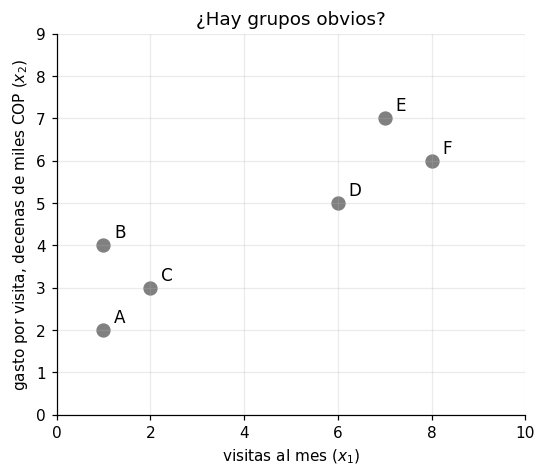

In [8]:
XLIM1, YLIM1 = (0, 10), (0, 9)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(X1[:, 0], X1[:, 1], s=70, color="gray")
for (x, y), nom in zip(X1, nombres1):
    ax.annotate(nom, (x, y), textcoords="offset points", xytext=(7, 5), fontsize=11)
ax.set(xlim=XLIM1, ylim=YLIM1, xlabel="visitas al mes ($x_1$)",
       ylabel="gasto por visita, decenas de miles COP ($x_2$)",
       title="¿Hay grupos obvios?")
plt.show()

### El algoritmo de Lloyd, paso a paso

Se repiten dos pasos hasta que las asignaciones dejen de cambiar:

1. **Asignación:** $c_i=\arg\min_j \lVert\mathbf{x}_i-\boldsymbol{\mu}_j\rVert^2$.
2. **Actualización:** $\boldsymbol{\mu}_j=\dfrac{1}{|C_j|}\sum_{i\in C_j}\mathbf{x}_i$.

Para que el algoritmo tenga algo que corregir, usamos una **inicialización deliberadamente mala**: ambos centros arrancan en clientes del grupo que frecuenta más el supermercado, $\boldsymbol{\mu}_1^{(0)}=D=(6,5)$ y $\boldsymbol{\mu}_2^{(0)}=E=(7,7)$.

La celda siguiente imprime, en cada iteración, la tabla de distancias al cuadrado, el grupo asignado y la inercia después de cada paso.

In [10]:
k = 2
C = X1[[3, 4]].copy()            # inicialización: D y E
etiquetas_prev = None
historial = []

for it in range(1, 11):
    # ---- Paso 1: asignación ----
    etiquetas, d2 = asignar(X1, C)
    J_asig = inercia(X1, etiquetas, C)
    tabla = pd.DataFrame(d2, index=clientes.index, columns=[f"d² a μ{j+1}" for j in range(k)])
    tabla["grupo asignado"] = etiquetas + 1
    print(f"═══ ITERACIÓN {it} ═══")
    print("Centros actuales:\n", C)
    display(tabla)
    print(f"Inercia después de ASIGNAR: {J_asig:.3f}")

    # ---- Paso 2: actualización ----
    C_nuevo = actualizar(X1, etiquetas, k)
    J_act = inercia(X1, etiquetas, C_nuevo)
    print("Nuevos centroides (medias):\n", C_nuevo)
    print(f"Inercia después de ACTUALIZAR: {J_act:.3f}\n")

    historial.append(dict(it=it, C=C.copy(), etiquetas=etiquetas.copy(),
                          C_nuevo=C_nuevo.copy(), J_asig=J_asig, J_act=J_act))

    # ---- Criterio de parada: las asignaciones no cambiaron ----
    if etiquetas_prev is not None and np.array_equal(etiquetas, etiquetas_prev):
        print("✔ Las asignaciones no cambiaron: el algoritmo CONVERGIÓ.")
        break
    etiquetas_prev, C = etiquetas, C_nuevo

C_final1 = historial[-1]["C_nuevo"]
etiquetas_final1 = historial[-1]["etiquetas"]

═══ ITERACIÓN 1 ═══
Centros actuales:
 [[6. 5.]
 [7. 7.]]


,d² a μ1,d² a μ2,grupo asignado
cliente,,,
A,34.000,61.000,1
B,26.000,45.000,1
C,20.000,41.000,1
D,0.000,5.000,1
E,5.000,0.000,2
F,5.000,2.000,2


Inercia después de ASIGNAR: 82.000
Nuevos centroides (medias):
 [[2.5 3.5]
 [7.5 6.5]]
Inercia después de ACTUALIZAR: 23.000

═══ ITERACIÓN 2 ═══
Centros actuales:
 [[2.5 3.5]
 [7.5 6.5]]


,d² a μ1,d² a μ2,grupo asignado
cliente,,,
A,4.500,62.500,1
B,2.500,48.500,1
C,0.500,42.500,1
D,14.500,4.500,2
E,32.500,0.500,2
F,36.500,0.500,2


Inercia después de ASIGNAR: 13.000
Nuevos centroides (medias):
 [[1.333 3.   ]
 [7.    6.   ]]
Inercia después de ACTUALIZAR: 6.667

═══ ITERACIÓN 3 ═══
Centros actuales:
 [[1.333 3.   ]
 [7.    6.   ]]


,d² a μ1,d² a μ2,grupo asignado
cliente,,,
A,1.111,52.000,1
B,1.111,40.000,1
C,0.444,34.000,1
D,25.778,2.000,2
E,48.111,1.000,2
F,53.444,1.000,2


Inercia después de ASIGNAR: 6.667
Nuevos centroides (medias):
 [[1.333 3.   ]
 [7.    6.   ]]
Inercia después de ACTUALIZAR: 6.667

✔ Las asignaciones no cambiaron: el algoritmo CONVERGIÓ.


### Resumen de lo que pasó ahora en imágenes

Los colores indican el grupo; las regiones sombreadas son las **celdas de Voronoi** de los centros; la frontera discontinua es la mediatriz entre ellos; los rombos discontinuos son los centros anteriores y los rellenos corresponden a los nuevos.

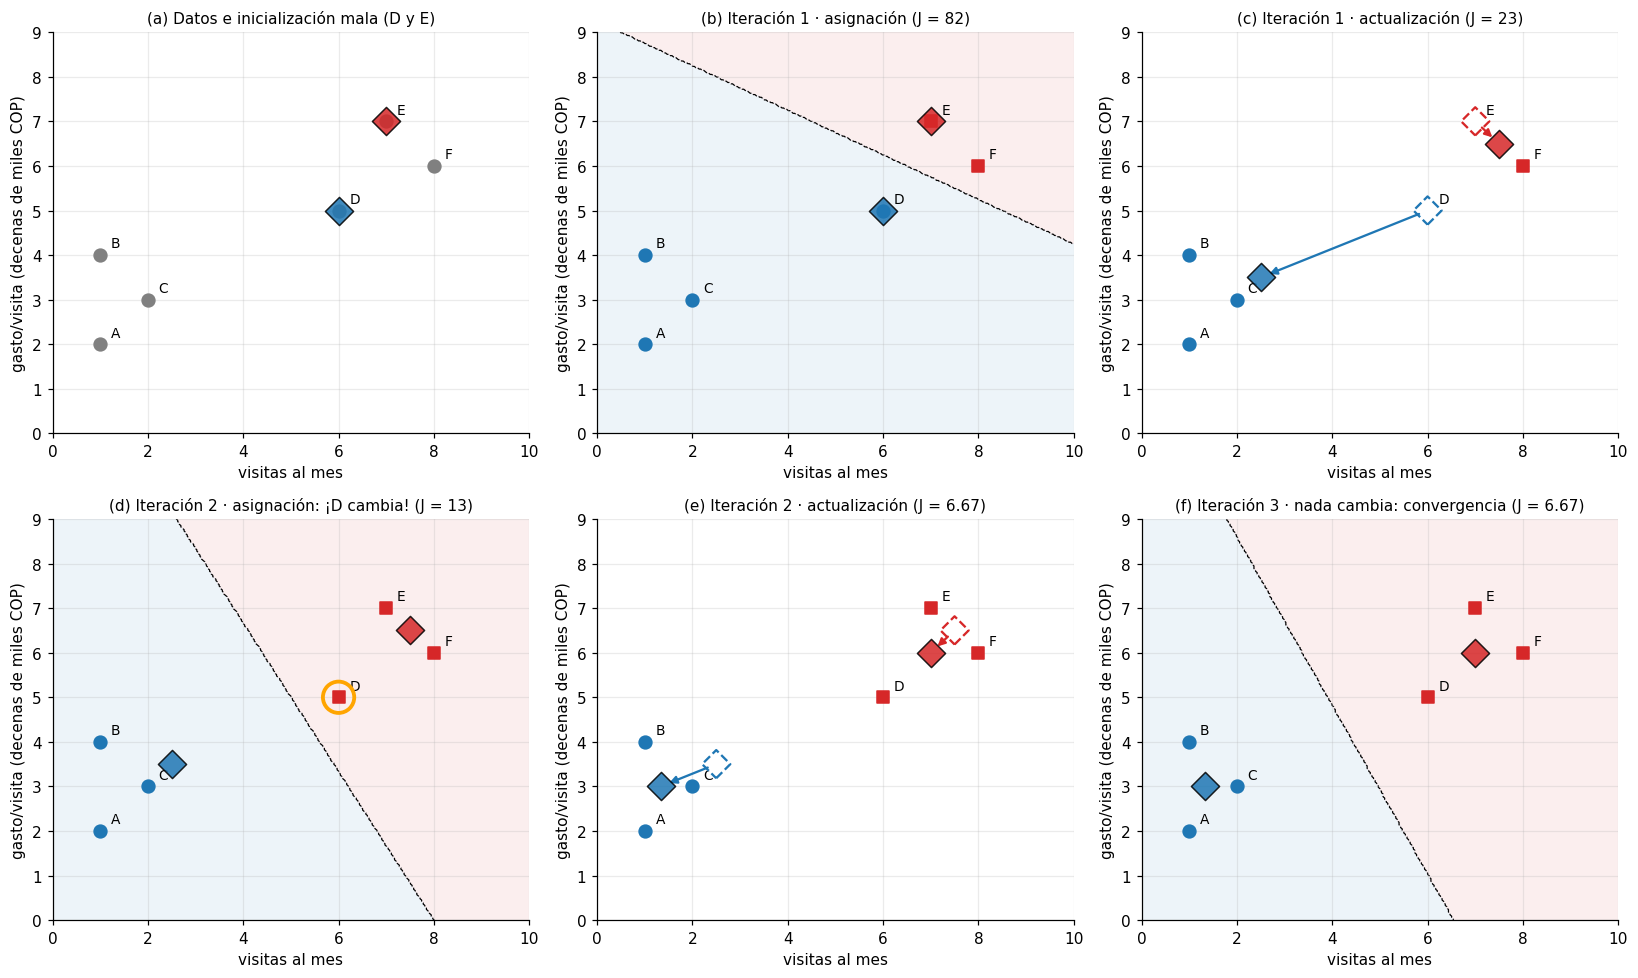

In [12]:
def dibujar_estado(ax, X, nombres, etiquetas, C, C_prev=None, titulo="", regiones=True,
                   xlim=XLIM1, ylim=YLIM1, resaltar=None):
    """Dibuja puntos (coloreados por grupo), centros y, opcionalmente, flechas de desplazamiento."""
    if regiones and C is not None:
        sombrear_regiones(ax, C, xlim, ylim)
    if etiquetas is None:
        ax.scatter(X[:, 0], X[:, 1], s=70, color="gray", zorder=3)
    else:
        for j in np.unique(etiquetas):
            m = etiquetas == j
            ax.scatter(X[m, 0], X[m, 1], s=70, color=PALETA[j], marker=MARCAS[j], zorder=3)
    for (x, y), nom in zip(X, nombres):
        ax.annotate(nom, (x, y), textcoords="offset points", xytext=(7, 5), fontsize=9, zorder=4)
    if C_prev is not None:
        for j, (c0, c1) in enumerate(zip(C_prev, C)):
            ax.scatter(*c0, s=170, marker="D", facecolor="white", edgecolor=PALETA[j],
                       linestyle="--", linewidth=1.5, zorder=5)
            ax.annotate("", xy=c1, xytext=c0, zorder=5,
                        arrowprops=dict(arrowstyle="-|>", color=PALETA[j], lw=1.5, shrinkA=6, shrinkB=6))
    if C is not None:
        for j, c in enumerate(C):
            ax.scatter(*c, s=170, marker="D", facecolor=PALETA[j], edgecolor="k", alpha=0.85, zorder=6)
    if resaltar is not None:
        ax.scatter(*X[resaltar], s=420, facecolor="none", edgecolor="orange", linewidth=2.5, zorder=7)
    ax.set(xlim=xlim, ylim=ylim, title=titulo, xlabel="visitas al mes", ylabel="gasto/visita (decenas de miles COP)")
    ax.title.set_fontsize(10)

h1, h2, h3 = historial[0], historial[1], historial[2]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
dibujar_estado(axes[0, 0], X1, nombres1, None, h1["C"], titulo="(a) Datos e inicialización mala (D y E)", regiones=False)
dibujar_estado(axes[0, 1], X1, nombres1, h1["etiquetas"], h1["C"], titulo=f"(b) Iteración 1 · asignación (J = {h1['J_asig']:.0f})")
dibujar_estado(axes[0, 2], X1, nombres1, h1["etiquetas"], h1["C_nuevo"], C_prev=h1["C"], regiones=False,
               titulo=f"(c) Iteración 1 · actualización (J = {h1['J_act']:.0f})")
dibujar_estado(axes[1, 0], X1, nombres1, h2["etiquetas"], h2["C"], resaltar=3,
               titulo=f"(d) Iteración 2 · asignación: ¡D cambia! (J = {h2['J_asig']:.0f})")
dibujar_estado(axes[1, 1], X1, nombres1, h2["etiquetas"], h2["C_nuevo"], C_prev=h2["C"], regiones=False,
               titulo=f"(e) Iteración 2 · actualización (J = {h2['J_act']:.2f})")
dibujar_estado(axes[1, 2], X1, nombres1, h3["etiquetas"], h3["C"],
               titulo=f"(f) Iteración 3 · nada cambia: convergencia (J = {h3['J_asig']:.2f})")
plt.tight_layout()
plt.show()

### La inercia nunca aumenta

Cada paso resuelve **exactamente** una de las dos incógnitas con la otra fija, así que $J$ no puede subir. Esto garantiza que el algoritmo termine, aunque solo llega a un **óptimo local**.

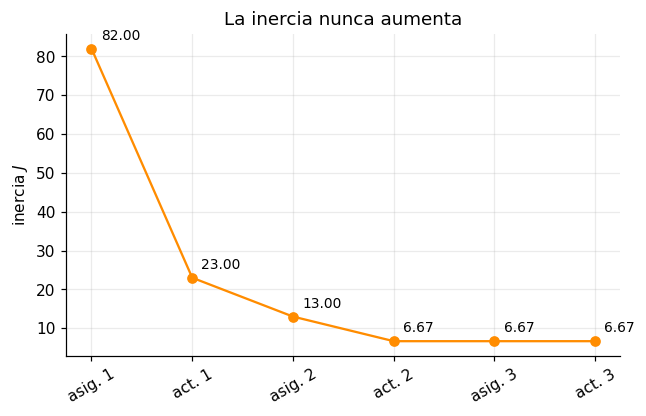

¿No creciente? True


In [14]:
J_secuencia, etiquetas_paso = [], []
for h in historial:
    J_secuencia += [h["J_asig"], h["J_act"]]
    etiquetas_paso += [f"asig. {h['it']}", f"act. {h['it']}"]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(range(len(J_secuencia)), J_secuencia, "o-", color="darkorange")
for i, J in enumerate(J_secuencia):
    ax.annotate(f"{J:.2f}", (i, J), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.set_xticks(range(len(J_secuencia)), etiquetas_paso, rotation=30)
ax.set(ylabel="inercia $J$", title="La inercia nunca aumenta")
plt.show()
print("¿No creciente?", all(a >= b - 1e-12 for a, b in zip(J_secuencia, J_secuencia[1:])))

###  Verificación con la función optimizada en scikit-learn

Pidiendo a `KMeans` los mismos centros iniciales (`init=` un arreglo, `n_init=1`) deberíamos obtener exactamente lo mismo que a mano.

In [16]:
km1 = KMeans(n_clusters=2, init=X1[[3, 4]], n_init=1, tol=0, random_state=SEED).fit(X1)
print("Centroides sklearn:\n", km1.cluster_centers_)
print("Centroides a mano :\n", C_final1)
print(f"Inercia sklearn: {km1.inertia_:.4f} | a mano: {inercia(X1, etiquetas_final1, C_final1):.4f}  (20/3 = {20/3:.4f})")
print("Mismas etiquetas:", np.array_equal(km1.labels_, etiquetas_final1))

Centroides sklearn:
 [[1.333 3.   ]
 [7.    6.   ]]
Centroides a mano :
 [[1.333 3.   ]
 [7.    6.   ]]
Inercia sklearn: 6.6667 | a mano: 6.6667  (20/3 = 6.6667)
Mismas etiquetas: True


In [37]:
pip install -U threadpoolctl scikit-learn joblib numpy# hacer esto si en la linea anterior se genera error

  Obtaining dependency information for threadpoolctl from https://files.pythonhosted.org/packages/54/1b/831f2de4840a25db1dd7b1afea433ccafe6bb10aca07e13264f2079462d0/threadpoolctl-3.8.0-py3-none-any.whl.metadata
  Obtaining dependency information for scikit-learn from https://files.pythonhosted.org/packages/23/31/dc50d8780ac647bed9417f10a8b15ae3cf990ad7edb4f4b468f35030f8c5/scikit_learn-1.9.1-cp311-cp311-macosx_12_0_arm64.whl.metadata
  Obtaining dependency information for joblib from https://files.pythonhosted.org/packages/18/53/84099323c2ec4be98d935f63c033ac4151ee83836ca1050ede3b3aadf155/joblib-1.6.0-py3-none-any.whl.metadata
  Obtaining dependency information for numpy from https://files.pythonhosted.org/packages/ad/40/40a40ee0ddf7ceb782c49af278894b686e586d65d8c1889c8b5da01a3d7d/numpy-2.4.6-cp311-cp311-macosx_14_0_arm64.whl.metadata
  Obtaining dependency information for narwhals>=2.0.1 from https://files.pythonhosted.org/packages/cf/82/8ef9c7e0f50493307a49c09cfa7f00c5a778b6d1921f7b2d

### ¿Qué tan buena es la agrupación obtenida? 

La varianza total se descompone en una parte **intra-grupo** ($W=J$) y una **inter-grupo** ($B$):

$$\underbrace{\sum_i\lVert\mathbf{x}_i-\bar{\mathbf{x}}\rVert^2}_{\text{TSS}}=\underbrace{\sum_j\sum_{i\in C_j}\lVert\mathbf{x}_i-\boldsymbol{\mu}_j\rVert^2}_{W}+\underbrace{\sum_j|C_j|\,\lVert\boldsymbol{\mu}_j-\bar{\mathbf{x}}\rVert^2}_{B}$$

El cociente $B/\text{TSS}$ es el análogo del $R^2$ de la regresión. La **silueta** de cada punto compara su distancia media a su propio grupo ($a$) con la distancia media al grupo vecino más cercano ($b$): $s=(b-a)/\max(a,b)$.

In [18]:
media_global = X1.mean(axis=0)
TSS = ((X1 - media_global) ** 2).sum()
W = inercia(X1, etiquetas_final1, C_final1)
B = sum((etiquetas_final1 == j).sum() * ((C_final1[j] - media_global) ** 2).sum() for j in range(2))
print(f"TSS = {TSS:.3f} | W (intra) = {W:.3f} | B (inter) = {B:.3f} | W + B = {W + B:.3f}")
print(f"B / TSS = {B / TSS:.3f}  → la agrupación 'explica' el {100 * B / TSS:.1f} % de la variabilidad total")
print(f"Con k = 1 la inercia sería TSS = {TSS:.2f}; con k = 2 es {W:.2f}.\n")

s = silhouette_samples(X1, etiquetas_final1)
display(pd.DataFrame({"grupo": etiquetas_final1 + 1, "silueta": s}, index=clientes.index))
print(f"Silueta media = {s.mean():.3f}  (cercana a 1 = estructura fuerte)")

TSS = 68.333 | W (intra) = 6.667 | B (inter) = 61.667 | W + B = 68.333
B / TSS = 0.902  → la agrupación 'explica' el 90.2 % de la variabilidad total
Con k = 1 la inercia sería TSS = 68.33; con k = 2 es 6.67.



,grupo,silueta
cliente,,
A,1,0.764
B,1,0.732
C,1,0.759
D,2,0.564
E,2,0.738
F,2,0.752


Silueta media = 0.718  (cercana a 1 = estructura fuerte)


###  Interpretación en el contexto del problema y cliente nuevo

Los centroides corresponden a los **perfiles** de cada grupo. Los nombres que se usan ("ocasionales", "frecuentes") los pone el analista, el que está haciendo el modelo,  **después** de mirar los centroides, dado que el algoritmo solo entregó las etiquetas 1 y 2.

In [22]:
perfil = pd.DataFrame(C_final1, columns=["visitas_mes", "gasto_decenas_miles"],
                      index=["Grupo 1", "Grupo 2"])
perfil["gasto_por_visita_COP"] = perfil["gasto_decenas_miles"] * 10_000
perfil["n_clientes"] = [(etiquetas_final1 == j).sum() for j in range(2)]

# gasto mensual aproximado, calculado cliente a cliente y luego promediado
gasto_mensual = clientes["visitas_mes"] * clientes["gasto_por_visita_COP"]
perfil["gasto_mensual_COP"] = [gasto_mensual[etiquetas_final1 == j].mean() for j in range(2)]
display(perfil)

# Cliente nuevo: 5 visitas al mes y 40 000 COP por visita
nuevo = np.array([[5, 4]], dtype=float)
etiqueta_nuevo, d2_nuevo = asignar(nuevo, C_final1)
print("Distancias² a los centroides:", d2_nuevo.ravel().round(2),
      f"→ se asigna al Grupo {etiqueta_nuevo[0] + 1} (el de mayor frecuencia de compra)")
print("scikit-learn dice:", km1.predict(nuevo) + 1)

,visitas_mes,gasto_decenas_miles,gasto_por_visita_COP,n_clientes,gasto_mensual_COP
Grupo 1,1.333,3.000,"30,000.000",3,"40,000.000"
Grupo 2,7.000,6.000,"60,000.000",3,"423,333.333"


Distancias² a los centroides: [14.44  8.  ] → se asigna al Grupo 2 (el de mayor frecuencia de compra)
scikit-learn dice: [2]


### ¿Qué pasa con la escala de las variables?

K-means se basa en distancias euclídeas, así que la escala de cada variable importa. Aquí el gasto se expresó en *decenas de miles* de pesos para que ambas variables fueran comparables. Veamos qué ocurre si el gasto se expresa en **pesos**.

In [25]:
Xp = X1.copy()
Xp[:, 1] *= 10_000                       # gasto en pesos
varianzas = Xp.var(axis=0)
aporte = varianzas / varianzas.sum()
print("Aporte de cada variable a la distancia cuadrática (gasto en pesos):")
print(pd.Series(aporte, index=["visitas_mes", "gasto (COP)"]).map("{:.10f}".format))

Z1 = StandardScaler().fit_transform(Xp)  # estandarizar corrige el problema
for nombre, datos in [("sin escalar (gasto en pesos)", Xp), ("estandarizado", Z1)]:
    km_ = KMeans(2, n_init=10, random_state=SEED).fit(datos)
    print(f"{nombre:30s} → grupos: {km_.labels_} | ARI vs. partición original = "
          f"{adjusted_rand_score(etiquetas_final1, km_.labels_):.2f}")

Aporte de cada variable a la distancia cuadrática (gasto en pesos):
visitas_mes    0.0000000290
gasto (COP)    0.9999999710
dtype: object
sin escalar (gasto en pesos)   → grupos: [0 0 0 1 1 1] | ARI vs. partición original = 1.00
estandarizado                  → grupos: [0 0 0 1 1 1] | ARI vs. partición original = 1.00


 ### Conclusión:
 
Con el gasto en pesos, la variable `visitas_mes` aporta ~0 % a las distancias: k-means ignora por completo las visitas. En este ejemplo la partición no cambia *por casualidad* (el gasto por sí solo ya separa los dos grupos), pero en general sí cambiaría. Por esto, la **regla práctica** es estandarizar las variables antes de agrupar, salvo que ya compartan unidades y escala con significado. Eso se hará en los siguientes ejemplos, partes 2 y 3.

---
# PARTE 2 · Segmentación de clientes con datos simulados 

Ahora el supermercado tiene **300 clientes** y queremos aplicar la técnica completa, pero usando solo sus elementos básicos. Escribiremos el algoritmo **desde cero** y lo compararemos con scikit-learn. Los pasos, pensando como el analista son los siguientes:

1. Definir la pregunta y generar/cargar los datos.
2. Explorar los datos (sin etiquetas).
3. Escalar las variables.
4. Implementar el algoritmo de Lloyd.
5. Ver cómo evoluciona (iteración a iteración).
6. Inicialización y reinicios múltiples (aleatoria vs. k-means++).
7. Comparar con `KMeans` de scikit-learn.
8. Elegir $k$ (codo y silueta).
9. Interpretar los grupos.
10. Validar y asignar clientes nuevos.

> **Nota sobre los datos.** Son **simulados** a propósito: así conocemos los segmentos "verdaderos" y podemos comprobar al final si k-means los recupera. Con datos reales (como veremos en la Parte 3) esos segmentos verdaderos normalmente no existen.

## 2.1 Los datos

Se simulan tres segmentos de clientes con comportamientos distintos; los llamaremos ocasionales, regulares y premium, y consideramos dos variables: visitas al mes y gasto por visita (miles de COP). Una observación importante: **los segmentos verdaderos se guardan aparte y no se usan para ajustar el modelo.**

In [35]:
rng = np.random.default_rng(SEED)

segmentos = {   # (media, desv. est.) de cada variable
    "ocasionales": dict(n=120, visitas=(2.0, 0.8), gasto=(35, 8)),
    "regulares":   dict(n=100, visitas=(8.0, 1.5), gasto=(55, 10)),
    "premium":     dict(n=80,  visitas=(5.0, 1.2), gasto=(140, 20)),
}

filas, y_verdadero = [], []
for nombre, p in segmentos.items():
    visitas = np.clip(rng.normal(*p["visitas"], p["n"]), 0.5, None)
    gasto = np.clip(rng.normal(*p["gasto"], p["n"]), 5, None)
    filas.append(np.c_[visitas, gasto])
    y_verdadero += [nombre] * p["n"]

X2 = np.vstack(filas)
y_verdadero = np.array(y_verdadero)
orden = rng.permutation(len(X2))                 # se mezclan los clientes
X2, y_verdadero = X2[orden], y_verdadero[orden]

datos2 = pd.DataFrame(X2, columns=["visitas_mes", "gasto_por_visita_miles"])
datos2.index.name = "cliente"
display(datos2.head())
display(datos2.describe().T)

,visitas_mes,gasto_por_visita_miles
cliente,,
0,2.295,37.508
1,1.697,33.209
2,6.243,69.759
3,7.854,63.568
4,1.470,46.260


,count,mean,std,min,25%,50%,75%,max
visitas_mes,300.000,4.840,2.883,0.500,2.186,4.652,7.365,12.358
gasto_por_visita_miles,300.000,68.640,44.292,17.822,35.963,50.353,107.395,180.701


## 2.2 Exploración inicial sin usar etiquetas

Dos cosas importan para k-means son: la **forma** de la nube, esto es, ¿hay grupos más o menos compactos? y la **escala** de las variables.

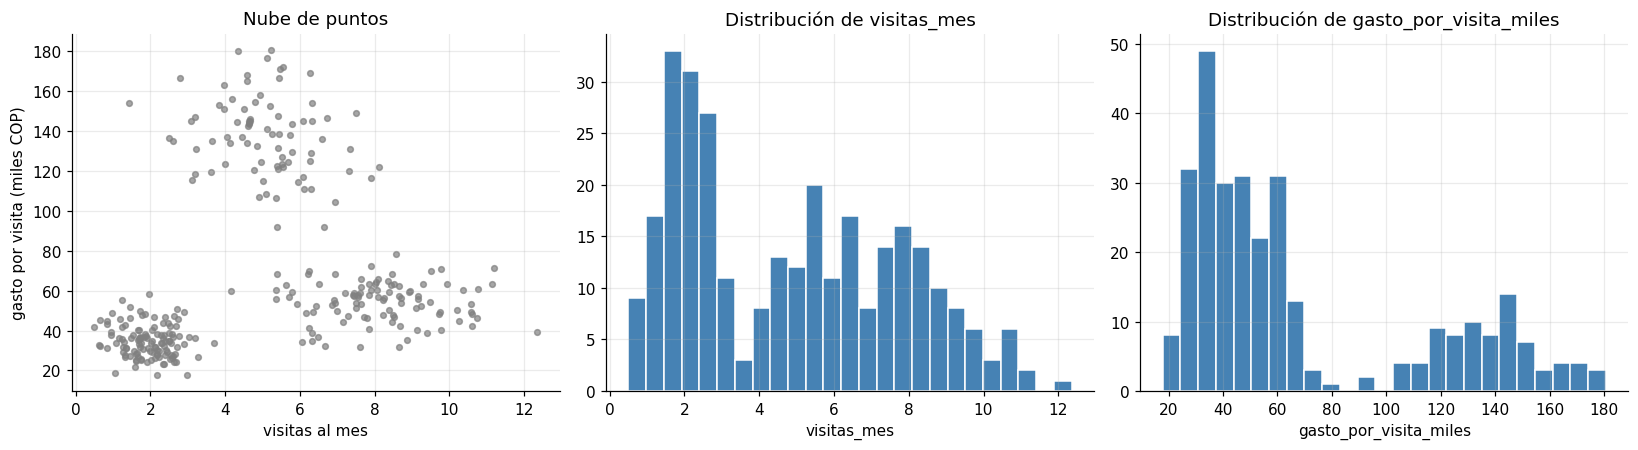

Rango de cada variable:
                           min     max   rango
visitas_mes             0.500  12.358  11.858
gasto_por_visita_miles 17.822 180.701 162.880


In [39]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].scatter(X2[:, 0], X2[:, 1], s=14, alpha=0.7, color="gray")
axes[0].set(xlabel="visitas al mes", ylabel="gasto por visita (miles COP)", title="Nube de puntos")
for j, col in enumerate(datos2.columns):
    axes[j + 1].hist(datos2[col], bins=25, color="steelblue", edgecolor="white")
    axes[j + 1].set(xlabel=col, title=f"Distribución de {col}")
plt.tight_layout(); plt.show()

print("Rango de cada variable:\n", datos2.agg(["min", "max"]).T.assign(rango=lambda d: d["max"] - d["min"]))

Las variables tienen rangos muy distintos (visitas: ~0–12; gasto: ~20–200). Sin escalar, el gasto dominaría las distancias.

## 2.3 Escalado (o estandarización)

Cada variable se transforma a $z=(x-\bar{x})/s$, de modo que tenga media 0 y desviación estándar 1. Es lo mismo que hace `StandardScaler`; lo hacemos a mano para ver qué ocurre.

In [43]:
mu, sigma = X2.mean(axis=0), X2.std(axis=0)     # ddof=0, igual que StandardScaler
Z2 = (X2 - mu) / sigma

print("Medias tras escalar :", Z2.mean(axis=0).round(10))
print("Desv. est. tras escalar:", Z2.std(axis=0))
print("¿Coincide con StandardScaler?", np.allclose(Z2, StandardScaler().fit_transform(X2)))

Medias tras escalar : [ 0. -0.]
Desv. est. tras escalar: [1. 1.]
¿Coincide con StandardScaler? True


## 2.4 El algoritmo de Lloyd desde cero

Las piezas son las del algoritmo de la teoría, más un detalle práctico: **qué hacer si un grupo se queda vacío** (rara vez pasa, pero hay que manejarlo; aquí el centro vacío se reubica en el punto más alejado de su centro actual).

Dos esquemas de inicialización:

* **Aleatoria (Forgy):** $k$ puntos de los datos elegidos al azar.
* **k-means++:** el primer centro es aleatorio; cada centro siguiente se elige con probabilidad proporcional a $D(\mathbf{x})^2$, el cuadrado de la distancia al centro más cercano ya elegido. Favorece centros bien dispersos.

In [45]:
def init_aleatoria(X, k, rng):
    return X[rng.choice(len(X), size=k, replace=False)].copy()

def init_kmeanspp(X, k, rng):
    n = len(X)
    C = [X[rng.integers(n)]]
    for _ in range(1, k):
        d2 = distancias_cuadradas(X, np.array(C)).min(axis=1)   # D(x)² al centro más cercano
        C.append(X[rng.choice(n, p=d2 / d2.sum())])              # prob. ∝ D(x)²
    return np.array(C)

def kmeans_lloyd(X, k, init="k-means++", max_iter=300, tol=1e-8, rng=None):
    """K-means con el algoritmo de Lloyd. Devuelve un diccionario con el resultado y el historial."""
    rng = np.random.default_rng() if rng is None else rng
    C = init_kmeanspp(X, k, rng) if init == "k-means++" else init_aleatoria(X, k, rng)
    historial = []
    for it in range(1, max_iter + 1):
        etiquetas, d2 = asignar(X, C)                                   # 1) asignación
        # manejo de grupos vacíos: el centro vacío pasa al punto peor representado
        for j in range(k):
            if not (etiquetas == j).any():
                peor = d2[np.arange(len(X)), etiquetas].argmax()
                C[j] = X[peor]
                etiquetas, d2 = asignar(X, C)
        historial.append(dict(it=it, C=C.copy(), etiquetas=etiquetas.copy(),
                              J=inercia(X, etiquetas, C)))
        C_nuevo = actualizar(X, etiquetas, k)                           # 2) actualización
        desplazamiento = np.sqrt(((C_nuevo - C) ** 2).sum(axis=1)).max()
        C = C_nuevo
        if desplazamiento <= tol:                                       # 3) convergencia
            break
    etiquetas, _ = asignar(X, C)
    return dict(C=C, etiquetas=etiquetas, inercia=inercia(X, etiquetas, C),
                n_iter=it, historial=historial)

res = kmeans_lloyd(Z2, k=3, init="aleatoria", rng=np.random.default_rng(1))
print(f"Convergió en {res['n_iter']} iteraciones | inercia final J = {res['inercia']:.2f}")
print("Tamaño de los grupos:", np.bincount(res["etiquetas"]))

Convergió en 4 iteraciones | inercia final J = 72.78
Tamaño de los grupos: [ 79 100 121]


## 2.5 Cómo evoluciona el algoritmo

Ahora vamos a mostrar los estados sucesivos en el espacio estandarizado. Observe cómo los centros (rombos) se desplazan hacia el centro de sus nubes y las fronteras se reacomodan.

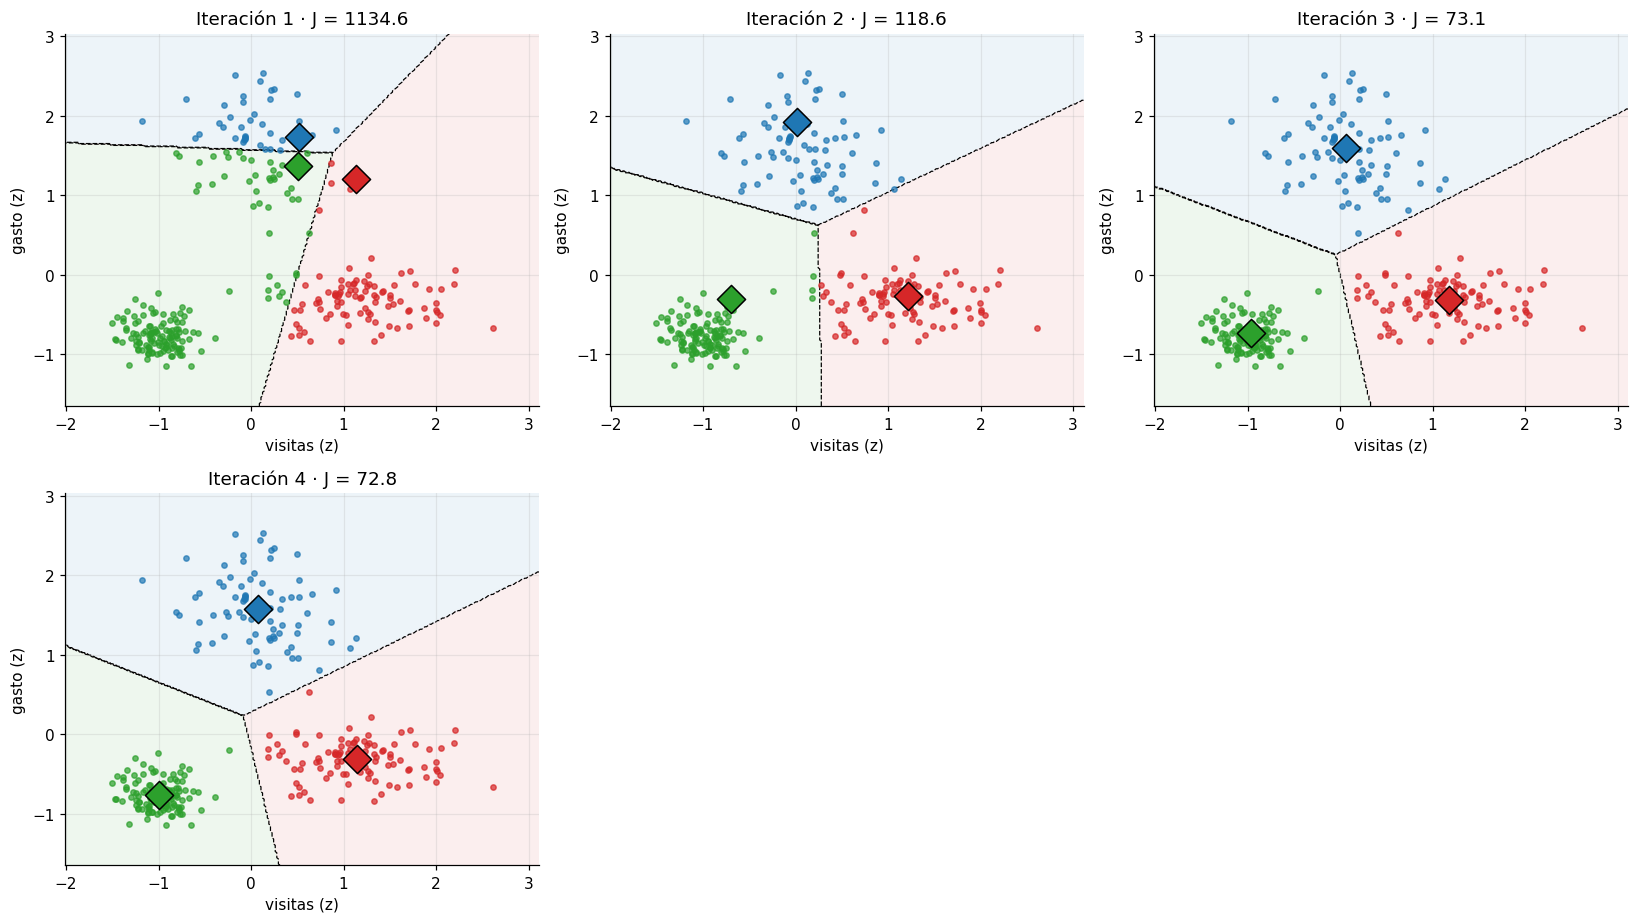

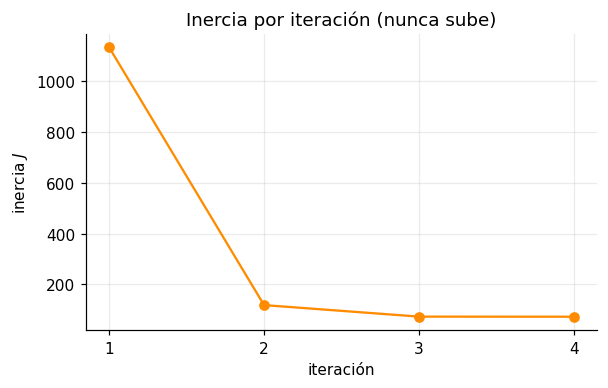

In [48]:
hist = res["historial"]
paneles = hist[: min(6, len(hist))]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
xl = (Z2[:, 0].min() - 0.5, Z2[:, 0].max() + 0.5)
yl = (Z2[:, 1].min() - 0.5, Z2[:, 1].max() + 0.5)
for ax, h in zip(axes.ravel(), paneles):
    sombrear_regiones(ax, h["C"], xl, yl)
    for j in range(3):
        m = h["etiquetas"] == j
        ax.scatter(Z2[m, 0], Z2[m, 1], s=12, color=PALETA[j], alpha=0.7, zorder=3)
    for j, c in enumerate(h["C"]):
        ax.scatter(*c, s=170, marker="D", facecolor=PALETA[j], edgecolor="k", zorder=6)
    ax.set(xlim=xl, ylim=yl, title=f"Iteración {h['it']} · J = {h['J']:.1f}",
           xlabel="visitas (z)", ylabel="gasto (z)")
for ax in axes.ravel()[len(paneles):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot([h["it"] for h in hist], [h["J"] for h in hist], "o-", color="darkorange")
ax.set(xlabel="iteración", ylabel="inercia $J$", title="Inercia por iteración (nunca sube)",
       xticks=[h["it"] for h in hist])
plt.show()

## 2.6 Inicialización y reinicios múltiples

K-means converge a un **óptimo local**, que depende de los centros iniciales. La receta estándar es como sigue: ejecutar el algoritmo **muchas veces** con inicializaciones distintas y **quedarse con la corrida de menor inercia**. Comparemos las dos estrategias de inicialización con 100 corridas independientes cada una.

,J mínima,J máxima,% de corridas que alcanzan el mejor J
Aleatoria,72.783,276.167,89.000
k-means++,72.783,72.783,100.000


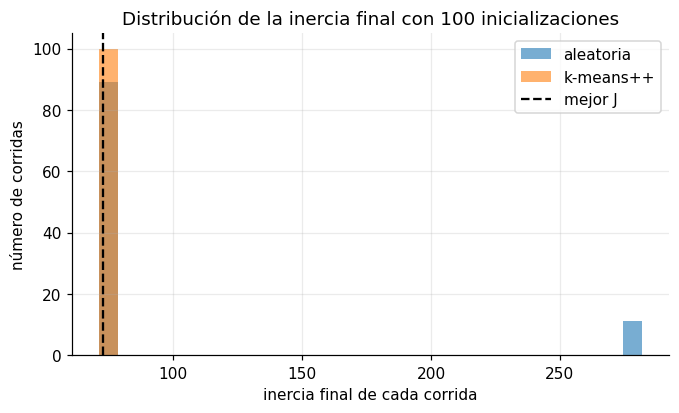

In [55]:
n_corridas = 100
J_aleatoria = np.array([kmeans_lloyd(Z2, 3, "aleatoria", rng=np.random.default_rng(s))["inercia"] for s in range(n_corridas)])
J_pp        = np.array([kmeans_lloyd(Z2, 3, "k-means++", rng=np.random.default_rng(s))["inercia"] for s in range(n_corridas)])
J_mejor = min(J_aleatoria.min(), J_pp.min())

resumen = pd.DataFrame({
    "J mínima": [J_aleatoria.min(), J_pp.min()],
    "J máxima": [J_aleatoria.max(), J_pp.max()],
    "% de corridas que alcanzan el mejor J": [100 * np.mean(J_aleatoria <= J_mejor * 1.0001),
                                              100 * np.mean(J_pp <= J_mejor * 1.0001)],
}, index=["Aleatoria", "k-means++"])
display(resumen)

fig, ax = plt.subplots(figsize=(7, 3.8))
bins = np.linspace(J_mejor * 0.98, max(J_aleatoria.max(), J_pp.max()) * 1.02, 30)
ax.hist(J_aleatoria, bins=bins, alpha=0.6, label="aleatoria", color="C0")
ax.hist(J_pp, bins=bins, alpha=0.6, label="k-means++", color="C1")
ax.axvline(J_mejor, color="k", ls="--", label="mejor J")
ax.set(xlabel="inercia final de cada corrida", ylabel="número de corridas",
       title="Distribución de la inercia final con 100 inicializaciones")
ax.legend(); plt.show()

> **Observación:** Algunas inicializaciones atrapan al algoritmo en soluciones peores (inercia mayor), sobre todo con la inicialización aleatoria. Con **varios reinicios** y quedándose con el mejor resultado, el riesgo prácticamente desaparece. En scikit-learn esto es el parámetro `n_init`.

### Por lo anterior, vamos a definir una función que haga exactamente eso y la compararemos con scikit-learn.

In [60]:
def kmeans_mejor_de(X, k, n_init=10, init="k-means++", seed=SEED):
    """Mejor de n_init corridas (menor inercia)."""
    rng = np.random.default_rng(seed)
    return min((kmeans_lloyd(X, k, init, rng=rng) for _ in range(n_init)), key=lambda r: r["inercia"])

mejor3 = kmeans_mejor_de(Z2, 3, n_init=10)
print(f"Nuestra implementación (mejor de 10): J = {mejor3['inercia']:.4f}")

Nuestra implementación (mejor de 10): J = 72.7829


## 2.7 Comparación con scikit-learn

Si nuestra implementación es correcta, debe encontrar la misma partición que `KMeans` (salvo permutación de etiquetas, por eso se compara con el **ARI**, que es invariante a renombrar los grupos).

In [63]:
km_sk = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=SEED).fit(Z2)
print(f"scikit-learn : J = {km_sk.inertia_:.4f}  (n_iter = {km_sk.n_iter_})")
print(f"nuestra      : J = {mejor3['inercia']:.4f}  (n_iter = {mejor3['n_iter']})")
print(f"ARI entre ambas particiones = {adjusted_rand_score(km_sk.labels_, mejor3['etiquetas']):.4f}  (1 = idénticas)")

scikit-learn : J = 72.7829  (n_iter = 4)
nuestra      : J = 72.7829  (n_iter = 3)
ARI entre ambas particiones = 1.0000  (1 = idénticas)


## 2.8 La pregunta importante: ¿cuántos grupos? 

En una situación real **no conocemos $k$**. Recordemos que la inercia *siempre* baja al aumentar $k$ (con $k=n$ vale 0), así que no se puede escoger $k$ minimizándola. Para esto usamos dos criterios:

* **Codo:** el punto donde añadir un grupo más deja de reducir mucho la inercia.
* **Silueta media:** $\bar{s}$ para cada $k\ge2$; se busca el máximo.

### Cómo se calcula la silueta de un punto

Para el cliente $i$: $a(i)$ = distancia media a los demás de su grupo; $b(i)$ = distancia media al grupo vecino más cercano; $s(i)=\dfrac{b(i)-a(i)}{\max\{a(i),b(i)\}}$.

In [66]:
def silueta_punto(Z, etiquetas, i):
    d = np.sqrt(((Z - Z[i]) ** 2).sum(axis=1))
    propio = (etiquetas == etiquetas[i]) & (np.arange(len(Z)) != i)
    a = d[propio].mean()
    b = min(d[etiquetas == c].mean() for c in np.unique(etiquetas) if c != etiquetas[i])
    return (b - a) / max(a, b), a, b

i = 0
s_i, a_i, b_i = silueta_punto(Z2, mejor3["etiquetas"], i)
print(f"Cliente {i}: a = {a_i:.3f}, b = {b_i:.3f}  →  s = {s_i:.3f}")
print(f"silhouette_samples de scikit-learn: {silhouette_samples(Z2, mejor3['etiquetas'])[i]:.3f}")

Cliente 0: a = 0.286, b = 2.086  →  s = 0.863
silhouette_samples de scikit-learn: 0.863


,inercia,silueta
k,,
1,600.000,NaN
2,280.495,0.558
3,72.783,0.718
4,55.628,0.616
5,42.994,0.557
6,37.175,0.538
7,31.999,0.539
8,28.031,0.369


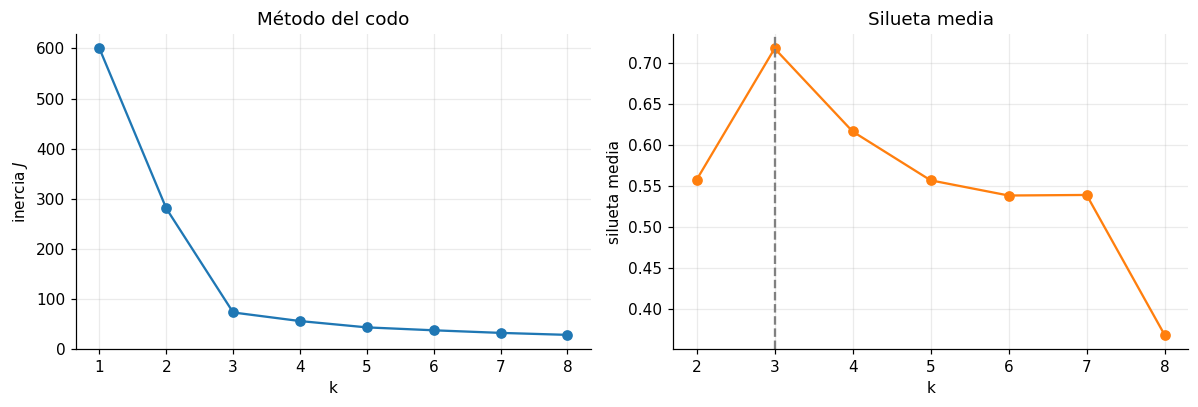

Máxima silueta en k = 3


In [68]:
resultados_k = []
for k in range(1, 9):
    r = kmeans_mejor_de(Z2, k, n_init=10)
    resultados_k.append(dict(k=k, inercia=r["inercia"],
                             silueta=silhouette_score(Z2, r["etiquetas"]) if k > 1 else np.nan))
tabla_k = pd.DataFrame(resultados_k).set_index("k")
display(tabla_k)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(tabla_k.index, tabla_k["inercia"], "o-")
axes[0].set(xlabel="k", ylabel="inercia $J$", title="Método del codo")
axes[1].plot(tabla_k.index, tabla_k["silueta"], "o-", color="C1")
axes[1].set(xlabel="k", ylabel="silueta media", title="Silueta media")
k_sil = int(tabla_k["silueta"].idxmax())
axes[1].axvline(k_sil, color="gray", ls="--")
plt.tight_layout(); plt.show()
print(f"Máxima silueta en k = {k_sil}")

> **Observación** Tanto el codo como la silueta señalan $k=3$. Con datos reales los criterios no siempre coinciden (lo veremos en el ejemplo de la Parte 3) y hay que combinarlos con el conocimiento del problema para estimar el buen $k$.

## 2.9 Modelo final e interpretación

Con $k=3$ ajustamos el modelo final y **volvemos a las unidades originales** (los centroides en el espacio estandarizado no son interpretables). Como las etiquetas 0, 1, 2 son arbitrarias, las ordenamos por gasto mensual aproximado y les ponemos nombre (RECUERDE que los nombres los decide el analista (**USTED**), aquí se automatizan para que el notebook sea reproducible).

,visitas_mes,gasto_por_visita_miles,n_clientes,gasto_mensual_aprox_miles
ocasionales,1.970,34.937,121,68.837
premium,5.058,138.022,79,698.096
regulares,8.141,54.610,100,444.589


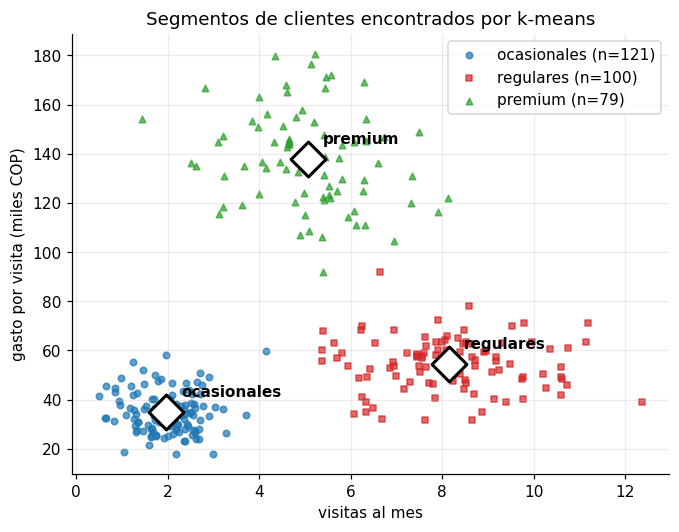

In [72]:
final = kmeans_mejor_de(Z2, 3, n_init=25)
C_orig = final["C"] * sigma + mu                       # centroides en unidades originales

gasto_mensual_c = C_orig[:, 0] * C_orig[:, 1]          # visitas × gasto por visita (aprox.)
rango = np.argsort(np.argsort(gasto_mensual_c))        # 0 = menor gasto mensual
nombres_grupo = np.array(["ocasionales", "regulares", "premium"])
etiq_nombre = nombres_grupo[rango[final["etiquetas"]]]

perfil2 = (pd.DataFrame(C_orig, columns=["visitas_mes", "gasto_por_visita_miles"],
                        index=nombres_grupo[rango]).sort_values("visitas_mes"))
perfil2["n_clientes"] = pd.Series(etiq_nombre).value_counts()
perfil2["gasto_mensual_aprox_miles"] = perfil2["visitas_mes"] * perfil2["gasto_por_visita_miles"]
display(perfil2)

fig, ax = plt.subplots(figsize=(7, 5.2))
for nombre, color, m in zip(nombres_grupo, PALETA, MARCAS):
    msk = etiq_nombre == nombre
    ax.scatter(X2[msk, 0], X2[msk, 1], s=18, alpha=0.7, color=color, marker=m, label=f"{nombre} (n={msk.sum()})")
for (x, y), nombre in zip(C_orig, nombres_grupo[rango]):
    ax.scatter(x, y, s=260, marker="D", facecolor="white", edgecolor="k", linewidth=2, zorder=5)
    ax.annotate(nombre, (x, y), textcoords="offset points", xytext=(10, 10), fontweight="bold")
ax.set(xlabel="visitas al mes", ylabel="gasto por visita (miles COP)", title="Segmentos de clientes encontrados por k-means")
ax.legend(); plt.show()

## 2.10 Validación y clientes nuevos

**Validación (solo posible aquí porque los datos son simulados).** Comparamos los grupos con los segmentos verdaderos, que k-means nunca vio.

In [74]:
display(pd.crosstab(pd.Series(y_verdadero, name="segmento verdadero"), pd.Series(etiq_nombre, name="grupo k-means")))
print(f"ARI = {adjusted_rand_score(y_verdadero, etiq_nombre):.3f}")

grupo k-means,ocasionales,premium,regulares
segmento verdadero,,,
ocasionales,120,0,0
premium,0,79,1
regulares,1,0,99


ARI = 0.980


**Clientes nuevos.** Para asignar un cliente nuevo hay que aplicarle **la misma transformación** de escalado (con la media y desviación *del entrenamiento*, no las suyas) y luego buscar el centroide más cercano.

In [76]:
nuevos = np.array([[1.0, 30.0],     # pocas visitas, gasto bajo
                   [9.0, 60.0],     # muchas visitas, gasto medio
                   [5.0, 160.0],    # visitas moderadas, gasto muy alto
                   [11.0, 190.0]])  # caso extremo
Z_nuevos = (nuevos - mu) / sigma     # ¡mismo mu y sigma del entrenamiento!
etiq_n, d2_n = asignar(Z_nuevos, final["C"])
salida = pd.DataFrame(nuevos, columns=["visitas_mes", "gasto_por_visita_miles"])
salida["grupo"] = nombres_grupo[rango[etiq_n]]
salida["distancia_al_centroide"] = np.sqrt(d2_n[np.arange(len(nuevos)), etiq_n])
display(salida)

,visitas_mes,gasto_por_visita_miles,grupo,distancia_al_centroide
0,1.000,30.000,ocasionales,0.355
1,9.000,60.000,regulares,0.322
2,5.000,160.000,premium,0.497
3,11.000,190.000,premium,2.376


## 2.11 Resumen: los elementos básicos de la técnica

| # | Elemento | Qué se hizo aquí |
|---|---|---|
| 1 | **Pregunta y datos** | Segmentar clientes por frecuencia y gasto |
| 2 | **Exploración** | Nube de puntos y distribuciones; detectar diferencias de escala |
| 3 | **Escalado** | Estandarización ($z$-scores) con parámetros guardados |
| 4 | **Algoritmo** | Lloyd: asignar ↔ actualizar hasta converger; manejo de grupos vacíos |
| 5 | **Inicialización y reinicios** | k-means++ y mejor de varias corridas (`n_init`) |
| 6 | **Elección de $k$** | Codo + silueta (nunca minimizar la inercia sola) |
| 7 | **Interpretación** | Centroides en unidades originales, tamaños y nombres de grupo |
| 8 | **Validación y uso** | Comparación con la verdad (si existe); asignación de nuevos datos con el mismo escalado |

La Parte 3 repite este flujo con un **problema real** y añade lo que los datos reales exigen: calidad de datos, valores atípicos, estabilidad, criterios adicionales y validación externa.

---
# PARTE 3 · Un problema real: los pingüinos de Palmer (Antártida)

##  Contexto y planteamiento

**Los datos** corresponden a las medidas corporales de **344 pingüinos** de tres especies *Adelie*, *Chinstrap* y *Gentoo*, observados en el archipiélago Palmer, Antártida. Fueron recolectados por la Dra. Kristen Gorman y la Estación Palmer (Programa LTER) y popularizados como conjunto de datos en el paquete `palmerpenguins` (Horst, Hill y Gorman, 2020). Aquí se descargan de un  GitHub (repositorio `seaborn-data`).

**Las variables numéricas son:** longitud del pico (`bill_length_mm`), profundidad del pico (`bill_depth_mm`), longitud de la aleta (`flipper_length_mm`) y masa corporal (`body_mass_g`). 

**Las variables categóricas son:** especie, isla y sexo.

**Planteamos la pregunta exploratoria:** Usando solo las medidas corporales, ¿los pingüinos se agrupan de forma natural? ¿En cuántos grupos? ¿Qué caracteriza a cada uno?

**Regla de oro del clustering.** La especie **no se usa para entrenar ni para escoger $k$**. La guardamos aparte y la usamos solo al final como *validación externa*, algo que en un problema de clustering genuino normalmente no existe. Esto nos permite además ver con claridad cuándo las decisiones técnicas (escalado, $k$, etc.) ayudan o dañan.

**Flujo de trabajo de esta parte:** vamos a seguir casi la misma estructura del ejemplo de la parte 2, es bueno ir comparando o comparar al final para ver las similitudes y diferencias entre lo que se hace con datos sintéticos para aprender y lo que se hace y pasa con datos reales, donde se aprende más. A las malas, pero más.

1. Carga y calidad de datos ·
2. Exploración (EDA)
3. Escalado
4. Elección de $k$ (cuatro criterios)
5. Estabilidad
6. Sensibilidad a la inicialización
7. Modelo final
8. Perfilado e interpretación
9. Validación interna y externa
10. ¿Qué habría pasado si…?
11. Datos nuevos y despliegue
12. Conclusiones y limitaciones

### OJOOOOOOOO -> Mini-glosario PARA la Parte 3

Esta parte usará varias ideas, tecnicismos y técnicas que no se han visto ni aplicado antes en los otros modelos que hemos desarrollado. Cada una se explica en detalle justo donde aparece; aquí va la versión corta para ir preparados a encontrarlos en el camino:

| Término | En una línea | Dónde |
|---|---|---|
| **Bootstrap** | Simular "otra muestra" de los datos extrayendo filas *con reemplazo* de los datos originales | §3.5 |
| **ARI** (índice de Rand ajustado) | Qué tan parecidas son dos particiones, sin importar cómo se llamen los grupos: 1 = idénticas, ≈ 0 = parecido por puro azar | §3.5, §3.9 |
| **Sensibilidad a la inicialización** | Cuánto cambia el resultado según los centros con los que arranca el algoritmo | §3.6 |
| **Perfilado** | Describir cada grupo: tamaño, valores medios en unidades originales y qué lo distingue | §3.8 |
| **PCA** | Resumir varias variables en pocos ejes nuevos para poder *dibujar* los datos en 2D | §3.8 |
| **Validación externa** | Comparar los grupos con una referencia independiente que el modelo nunca vio (aquí, la especie) | §3.9 |
| **Mezcla gaussiana** | Modelo que describe los datos como la suma de $k$ "campanas" y da probabilidades de pertenencia en vez de una etiqueta única | §3.10 |

## 3.1 Carga de datos y calidad

In [83]:
URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
try:
    pinguinos = pd.read_csv(URL)
except Exception as e:                                   # plan B: seaborn (requiere internet o caché local)
    print("No se pudo leer la URL directamente:", e)
    pinguinos = sns.load_dataset("penguins")

print("Dimensiones:", pinguinos.shape)
display(pinguinos.head())
pinguinos.info()

Dimensiones: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.100,18.700,181.000,"3,750.000",MALE
1,Adelie,Torgersen,39.500,17.400,186.000,"3,800.000",FEMALE
2,Adelie,Torgersen,40.300,18.000,195.000,"3,250.000",FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.700,19.300,193.000,"3,450.000",FEMALE


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [85]:
variables = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

faltantes = pinguinos.isna().sum().to_frame("n_faltantes")
faltantes["%"] = 100 * faltantes["n_faltantes"] / len(pinguinos)
display(faltantes)

print("Filas con algún valor numérico faltante:")
display(pinguinos[pinguinos[variables].isna().any(axis=1)])

,n_faltantes,%
species,0,0.000
island,0,0.000
bill_length_mm,2,0.581
bill_depth_mm,2,0.581
flipper_length_mm,2,0.581
body_mass_g,2,0.581
sex,11,3.198


Filas con algún valor numérico faltante:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


**Decisión sobre los datos faltantes.** K-means no admite valores faltantes (no se puede calcular una distancia con entradas ausentes). Hay 2 pingüinos sin **ninguna** medida numérica, que no aportan información: los eliminamos (*listwise deletion*). Imputar valores (por ejemplo con la media) sería arriesgado en clustering porque puede **fabricar estructura**: todos los imputados caerían exactamente sobre el centro de la nube. El sexo faltante (11 casos) no es problema porque no es una variable de entrada.

Separamos además lo que **se usa para entrenar** (`X_df`) de lo que **solo se usa para interpretar/validar** (`meta`).

In [87]:
datos = pinguinos.dropna(subset=variables).reset_index(drop=True)
X_df = datos[variables].copy()                     # entrada del modelo
meta = datos[["species", "island", "sex"]].copy()  # NO se usa para entrenar

print(f"Filas tras eliminar faltantes: {len(datos)} (se eliminaron {len(pinguinos) - len(datos)})")
print("Filas duplicadas:", datos.duplicated().sum())
display(meta["species"].value_counts().to_frame("n (solo para validar al final)").T)

Filas tras eliminar faltantes: 342 (se eliminaron 2)
Filas duplicadas: 0


species,Adelie,Gentoo,Chinstrap
n (solo para validar al final),151,123,68


## 3.2 Exploración de datos (sin usar la especie)

Buscamos tres cosas relevantes para k-means: **escalas** de las variables, **asimetrías/valores atípicos** y **correlaciones**.

,count,mean,std,min,25%,50%,75%,max,asimetria
bill_length_mm,342.000,43.922,5.460,32.100,39.225,44.450,48.500,59.600,0.053
bill_depth_mm,342.000,17.151,1.975,13.100,15.600,17.300,18.700,21.500,-0.143
flipper_length_mm,342.000,200.915,14.062,172.000,190.000,197.000,213.000,231.000,0.346
body_mass_g,342.000,"4,201.754",801.955,"2,700.000","3,550.000","4,050.000","4,750.000","6,300.000",0.470


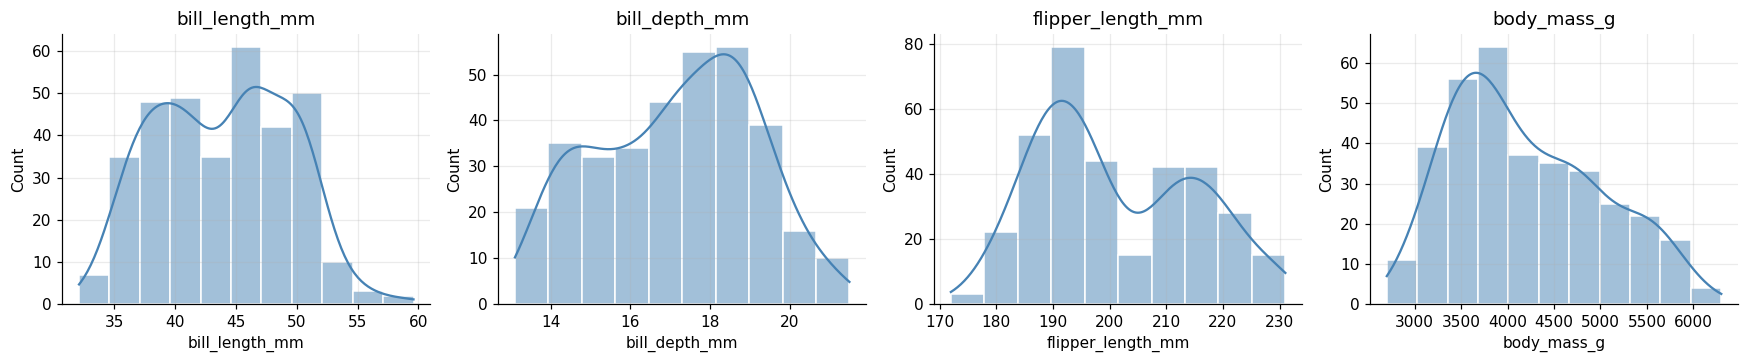

In [89]:
display(X_df.describe().T.assign(asimetria=X_df.skew()))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.4))
for ax, col in zip(axes, variables):
    sns.histplot(X_df[col], kde=True, ax=ax, color="steelblue", edgecolor="white")
    ax.set_title(col)
plt.tight_layout(); plt.show()

Observaciones atípicas por variable (regla 1.5·IQR):
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0


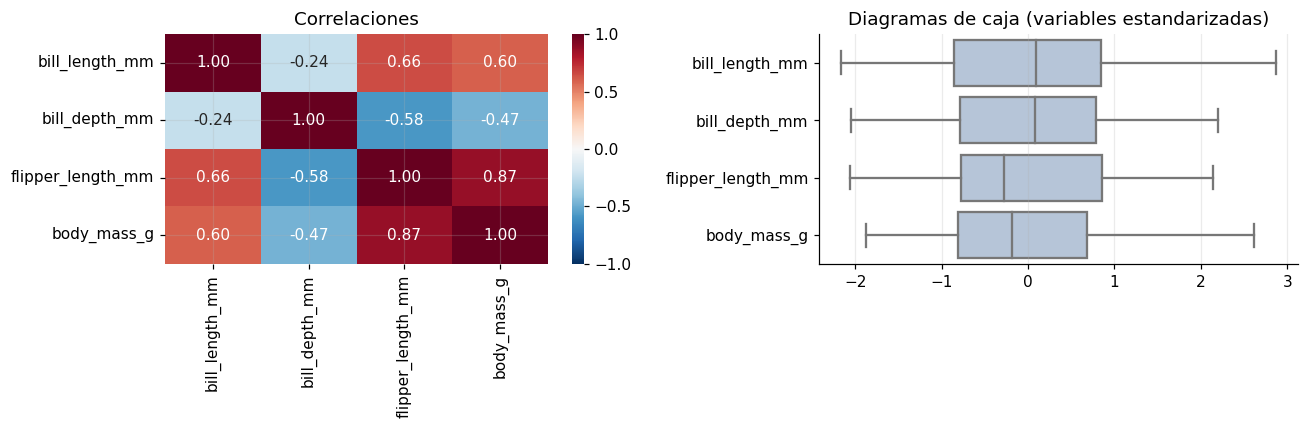

/Users/johnarredondo/anaconda3/lib/python3.11/site-packages/seaborn/axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


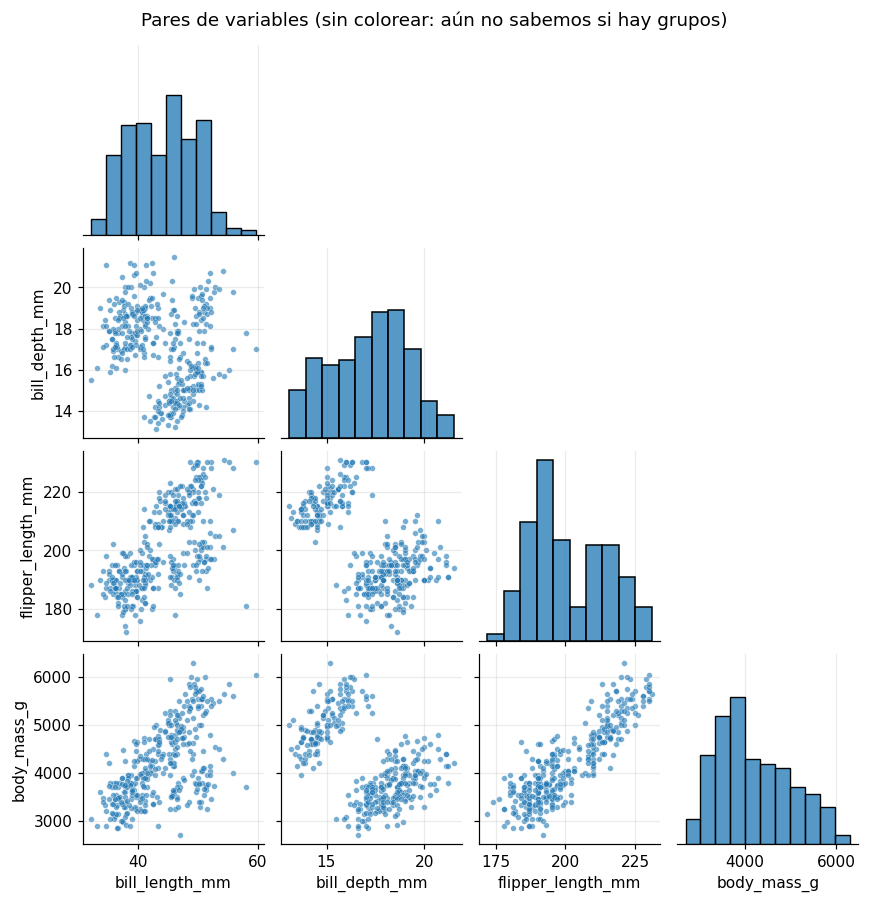

In [91]:
# Valores atípicos con la regla del rango intercuartílico (IQR)
q1, q3 = X_df.quantile(0.25), X_df.quantile(0.75)
iqr = q3 - q1
atipicos = ((X_df < q1 - 1.5 * iqr) | (X_df > q3 + 1.5 * iqr))
print("Observaciones atípicas por variable (regla 1.5·IQR):")
print(atipicos.sum().to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(X_df.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax[0])
ax[0].set_title("Correlaciones")
sns.boxplot(data=(X_df - X_df.mean()) / X_df.std(), orient="h", ax=ax[1], color="lightsteelblue")
ax[1].set_title("Diagramas de caja (variables estandarizadas)")
plt.tight_layout(); plt.show()

sns.pairplot(X_df, corner=True, plot_kws=dict(s=14, alpha=0.6), height=2.0)
plt.suptitle("Pares de variables (sin colorear: aún no sabemos si hay grupos)", y=1.02)
plt.show()

> **Hallazgos de la exploración.**
> * Las variables tienen escalas muy distintas: `body_mass_g` está en miles de gramos y `bill_depth_mm` en decenas de milímetros.
> * No hay observaciones atípicas extremas (la regla IQR no marca ninguna), de modo que no hace falta tratarlas.
> * Varias nubes de puntos muestran **separaciones o bultos**, lo que sugiere que hay estructura de grupos. Además `flipper_length_mm` y `body_mass_g` están muy correlacionadas (aportan información parecida).

## 3.3 Escalado: reindispensable aquí

Si no se escalan, cada variable aporta a la distancia euclídea en proporción a su **varianza**. Medimos cuánto aporta cada una a la distancia cuadrática media entre pares de pingüinos (que es proporcional a $\sigma_j^2/\sum_l\sigma_l^2$):

In [95]:
resumen_escala = pd.DataFrame({"media": X_df.mean(), "desv_est": X_df.std(), "min": X_df.min(), "max": X_df.max()})
resumen_escala["aporte a la distancia (sin escalar)"] = (X_df.var() / X_df.var().sum()).map("{:.4%}".format)
display(resumen_escala)

,media,desv_est,min,max,aporte a la distancia (sin escalar)
bill_length_mm,43.922,5.460,32.100,59.600,0.0046%
bill_depth_mm,17.151,1.975,13.100,21.500,0.0006%
flipper_length_mm,200.915,14.062,172.000,231.000,0.0307%
body_mass_g,"4,201.754",801.955,"2,700.000","6,300.000",99.9640%


Sin escalar, la **masa corporal** aporta prácticamente el 100 % de la distancia: k-means sería en la práctica un agrupamiento unidimensional por peso. Estandarizamos ($z=(x-\bar{x})/s$) para que las cuatro variables pesen lo mismo.

> **Importante para producción:** el escalador se **ajusta una sola vez** con los datos de entrenamiento y se reutiliza (con esa misma media y desviación) para cualquier dato nuevo. Por eso más adelante usamos un `Pipeline`.

In [97]:
escalador = StandardScaler().fit(X_df)
Z = escalador.transform(X_df)
Z_df = pd.DataFrame(Z, columns=variables)
display(Z_df.describe().loc[["mean", "std"]].T)

,mean,std
bill_length_mm,0.000,1.001
bill_depth_mm,-0.000,1.001
flipper_length_mm,-0.000,1.001
body_mass_g,0.000,1.001


## 3.4 ¿Cuántos grupos? Cuatro criterios

No existe un único criterio infalible. Calculamos, para $k=2,\dots,8$ (con 25 reinicios por cada $k$):

* **Inercia** (codo) · **Silueta media** (más alta es mejor) · **Calinski–Harabasz** (más alto es mejor) · **Davies–Bouldin** (más bajo es mejor) · y además el **estadístico gap**.

,inercia,silueta,calinski_harabasz,davies_bouldin
k,,,,
2,565.708,0.532,482.191,0.714
3,379.393,0.447,441.677,0.944
4,300.400,0.400,400.410,0.944
5,232.605,0.379,411.243,0.971
6,204.393,0.368,382.570,0.995
7,187.029,0.331,352.553,1.075
8,170.980,0.296,334.045,1.151


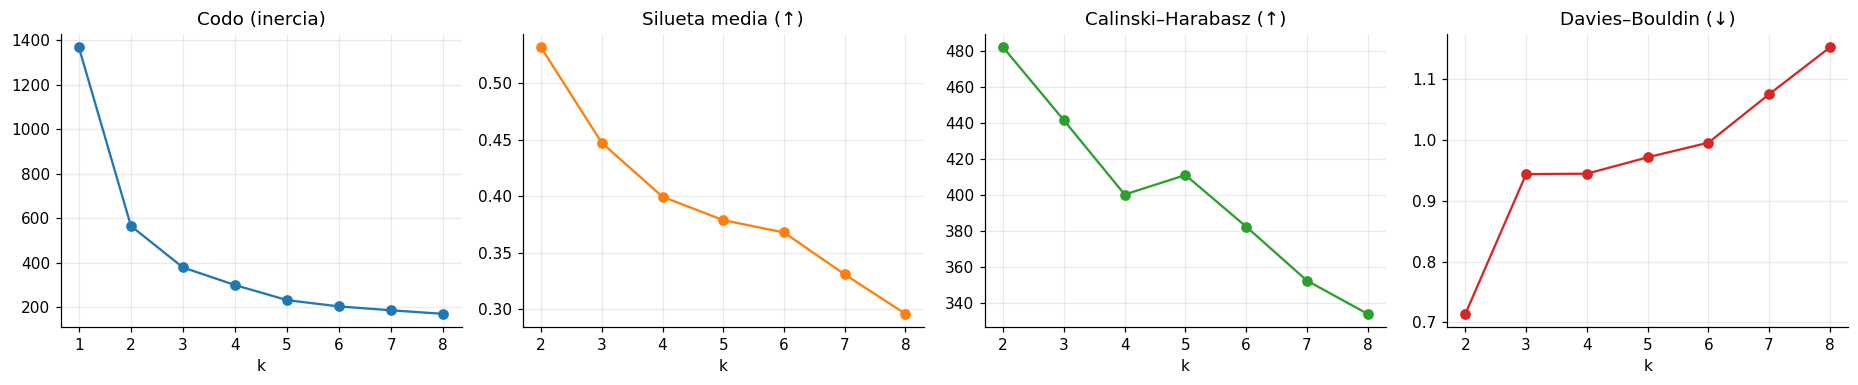

In [99]:
rango_k = list(range(2, 9))
modelos_k, filas = {}, []
for k in rango_k:
    km = KMeans(n_clusters=k, n_init=25, random_state=SEED).fit(Z)
    modelos_k[k] = km
    filas.append(dict(k=k, inercia=km.inertia_,
                      silueta=silhouette_score(Z, km.labels_),
                      calinski_harabasz=calinski_harabasz_score(Z, km.labels_),
                      davies_bouldin=davies_bouldin_score(Z, km.labels_)))
criterios = pd.DataFrame(filas).set_index("k")
inercia_k1 = float((Z ** 2).sum())                 # con k = 1 la inercia es la varianza total (TSS)
display(criterios)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
axes[0].plot([1] + rango_k, [inercia_k1] + criterios["inercia"].to_list(), "o-")
axes[0].set(title="Codo (inercia)", xlabel="k")
axes[1].plot(rango_k, criterios["silueta"], "o-", color="C1"); axes[1].set(title="Silueta media (↑)", xlabel="k")
axes[2].plot(rango_k, criterios["calinski_harabasz"], "o-", color="C2"); axes[2].set(title="Calinski–Harabasz (↑)", xlabel="k")
axes[3].plot(rango_k, criterios["davies_bouldin"], "o-", color="C3"); axes[3].set(title="Davies–Bouldin (↓)", xlabel="k")
plt.tight_layout(); plt.show()

### Estadístico gap

Compara la inercia observada con la que se esperaría en datos **sin estructura** (uniformes en el mismo rango). Se escoge el menor $k$ tal que $\text{Gap}(k)\ge\text{Gap}(k+1)-s_{k+1}$ (regla de Tibshirani et al.).

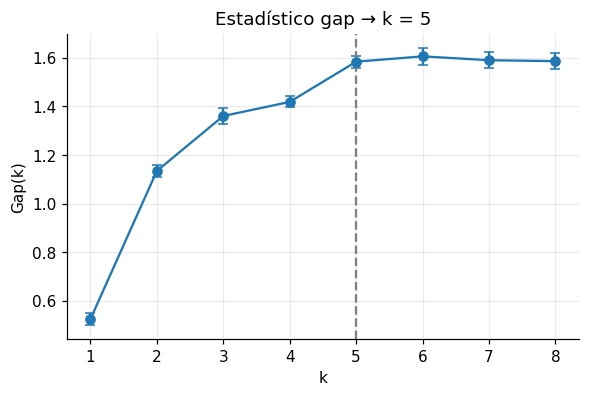

Gap(k) para k = 1..8: [0.525 1.135 1.361 1.419 1.584 1.606 1.59  1.586]
Regla de Tibshirani → k = 5


In [101]:
def estadistico_gap(Z, ks, B=20, n_init=5, seed=SEED):
    rng = np.random.default_rng(seed)
    lo, hi = Z.min(axis=0), Z.max(axis=0)
    gap, sk = [], []
    for k in ks:
        W = KMeans(k, n_init=n_init, random_state=seed).fit(Z).inertia_
        W_ref = [KMeans(k, n_init=n_init, random_state=seed)
                 .fit(rng.uniform(lo, hi, size=Z.shape)).inertia_ for _ in range(B)]
        logs = np.log(W_ref)
        gap.append(logs.mean() - np.log(W))
        sk.append(logs.std() * np.sqrt(1 + 1 / B))
    return np.array(gap), np.array(sk)

ks_gap = list(range(1, 9))
gap, sk = estadistico_gap(Z, ks_gap)
k_gap = next((k for i, k in enumerate(ks_gap[:-1]) if gap[i] >= gap[i + 1] - sk[i + 1]), ks_gap[-1])

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.errorbar(ks_gap, gap, yerr=sk, fmt="o-", capsize=3)
ax.axvline(k_gap, color="gray", ls="--")
ax.set(xlabel="k", ylabel="Gap(k)", title=f"Estadístico gap → k = {k_gap}")
plt.show()
print("Gap(k) para k = 1..8:", np.round(gap, 3))
print("Regla de Tibshirani → k =", k_gap)

### Diagramas de silueta

La silueta media resume todo en un número; el **diagrama de silueta** muestra cada observación (ordenada dentro de su grupo). Interesa que todos los grupos superen la media (línea roja), no tengan demasiados valores negativos y tengan anchos parecidos.

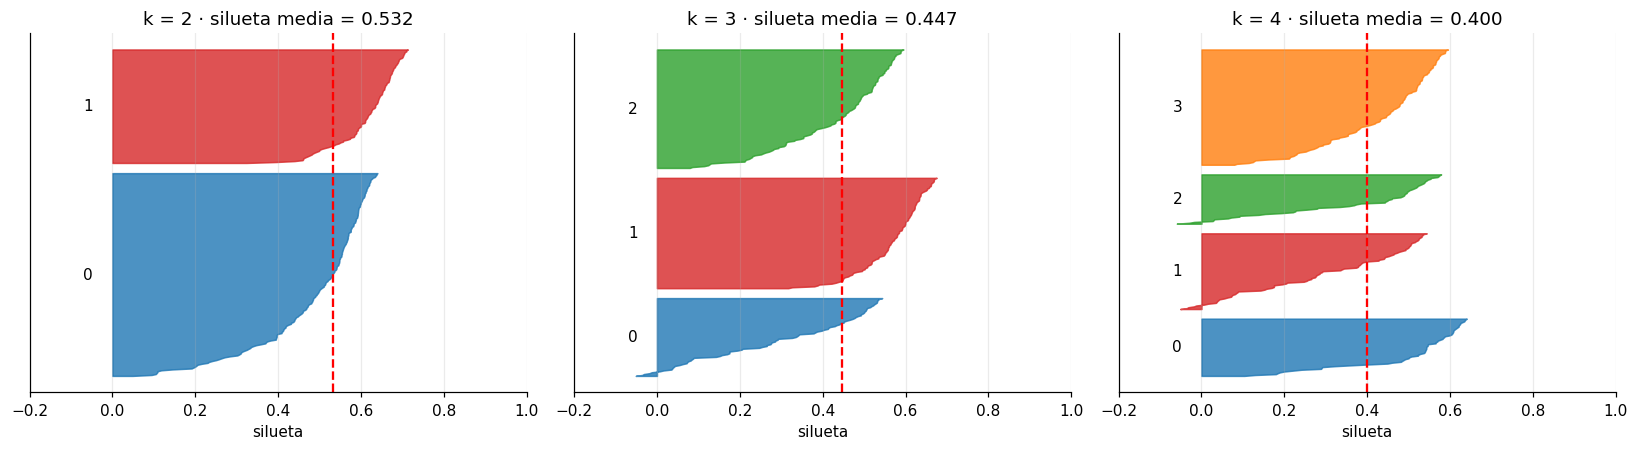

In [103]:
def diagrama_silueta(ax, Z, etiquetas, k):
    s = silhouette_samples(Z, etiquetas)
    y0 = 10
    for j in range(k):
        sj = np.sort(s[etiquetas == j])
        ax.fill_betweenx(np.arange(y0, y0 + len(sj)), 0, sj, color=PALETA[j], alpha=0.8)
        ax.text(-0.07, y0 + len(sj) / 2, str(j), va="center")
        y0 += len(sj) + 10
    ax.axvline(s.mean(), color="red", ls="--")
    ax.set(title=f"k = {k} · silueta media = {s.mean():.3f}", xlabel="silueta", xlim=(-0.2, 1), yticks=[])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, k in zip(axes, [2, 3, 4]):
    diagrama_silueta(ax, Z, modelos_k[k].labels_, k)
plt.tight_layout(); plt.show()

> **Importante.** Los criterios **no coinciden**, y eso es normal en datos reales: la silueta, Calinski–Harabasz y Davies–Bouldin prefieren $k=2$; el codo es poco nítido (la inercia cae mucho de $k=1$ a $k=2$, bastante de $k=2$ a $k=3$ y después de forma gradual); y la regla del estadístico gap (cuyo $\text{Gap}(k)$ sube rápido hasta $k=3$ y luego se aplana) termina escogiendo un $k$ mayor ($k=5$), una tendencia conocida de este criterio cuando los grupos no son perfectamente esféricos. La razón: dos especies (*Adelie* y *Chinstrap*) se parecen bastante entre sí y se separan de la tercera (*Gentoo*) con más claridad. Con $k=2$ obtenemos la separación más "limpia" y con $k=3$ una división más fina que es también razonable (y coincide con el número de especies, aunque ese dato no se usó para decidir).

> **Moraleja:** el $k$ no lo decide un solo número. Se combinan criterios, estabilidad (siguiente sección) e **interpretabilidad**. Aquí continuaremos con $k=3$ y compararemos con $k=2$ y $k=4$ en la sección 3.9.

## 3.5 Estabilidad: ¿los grupos se sostienen si cambian los datos?

Nuestros 342 pingüinos son una **muestra**: con otra muestra de la misma población los grupos saldrían algo distintos. Si una solución  es confiable debe **sobrevivir a ese cambio**; si los grupos se reorganizan por completo al cambiar unas pocas filas, probablemente reflejan ruido y no estructura real.

#### ¿Qué es el bootstrap?

Es un truco para simular "otra muestra" **sin recoger más datos**: se extraen $n$ filas **con reemplazo** de los datos originales. En cada remuestra algunas filas aparecen repetidas y otras no aparecen, de modo que cada remuestra es una versión plausible, ligeramente distinta, del conjunto de datos.

#### Procedimiento (para cada $k$, repetido 30 veces)

1. Crear dos remuestras bootstrap, A y B.
2. Ajustar k-means en A y otro k-means en B.
3. Usar cada modelo para asignar a **todos** los pingüinos originales (así ambas particiones cubren los mismos puntos).
4. Comparar las dos particiones con el **ARI** (índice de Rand ajustado): mide cuántas parejas de pingüinos quedan "juntas" o "separadas" de igual manera en ambas particiones, corregido por azar. No depende de cómo se numeren los grupos: **1 = particiones idénticas; ≈ 0 = parecido por puro azar**.

#### Cómo leer el resultado

ARI medio **alto** y poca dispersión → la solución es robusta. ARI **bajo o muy variable** → los grupos dependen de qué filas cayeron en la muestra: ese $k$ no es confiable.

,ARI medio,desv. est.,ARI mínimo
k,,,
2,1.000,0.002,0.988
3,0.911,0.061,0.811
4,0.764,0.161,0.532
5,0.896,0.058,0.764
6,0.838,0.094,0.602


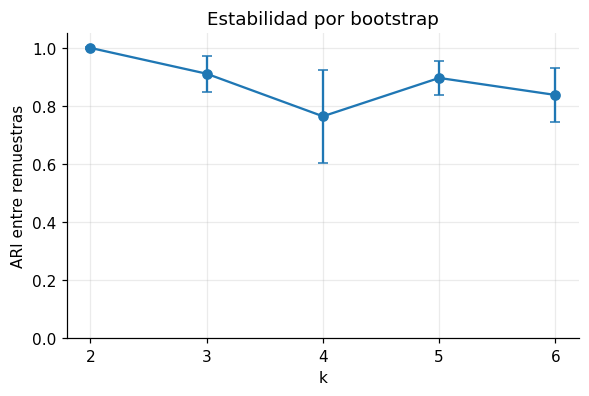

In [107]:
def estabilidad_bootstrap(Z, k, B=30, seed=SEED):
    rng = np.random.default_rng(seed)
    n, aris = len(Z), []
    for _ in range(B):
        m1 = KMeans(k, n_init=10, random_state=int(rng.integers(1_000_000))).fit(Z[rng.integers(0, n, n)])
        m2 = KMeans(k, n_init=10, random_state=int(rng.integers(1_000_000))).fit(Z[rng.integers(0, n, n)])
        aris.append(adjusted_rand_score(m1.predict(Z), m2.predict(Z)))
    return np.array(aris)

ks_est = [2, 3, 4, 5, 6]
est = {k: estabilidad_bootstrap(Z, k) for k in ks_est}
tabla_est = pd.DataFrame({"ARI medio": {k: v.mean() for k, v in est.items()},
                          "desv. est.": {k: v.std() for k, v in est.items()},
                          "ARI mínimo": {k: v.min() for k, v in est.items()}})
tabla_est.index.name = "k"
display(tabla_est)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.errorbar(ks_est, tabla_est["ARI medio"], yerr=tabla_est["desv. est."], fmt="o-", capsize=3)
ax.set(xlabel="k", ylabel="ARI entre remuestras", ylim=(0, 1.05), title="Estabilidad por bootstrap", xticks=ks_est)
plt.show()

Una estabilidad alta (ARI cerca de 1) indica que la partición es robusta. Con $k=2$ la solución es prácticamente idéntica en todas las remuestras (ARI ≈ 1), lo que concuerda con la silueta; con $k=3$ sigue siendo buena (ARI ≈ 0.9) pero con algo más de variación, y con $k=4$ es claramente la menos estable. La estabilidad no es necesariamente monótona en $k$ (aquí $k=5$ vuelve a subir), así que se interpreta junto con los demás criterios, no como una regla mecánica.

## 3.6 Sensibilidad a la inicialización

#### ¿Por qué importa dónde arranca el algoritmo?

La inercia $J$ tiene muchos "valles" (mínimos locales). El algoritmo de Lloyd siempre **baja** por el valle más cercano a su punto de partida y no puede saltar a otro: dos corridas con centros iniciales distintos pueden terminar en soluciones **diferentes**, y algunas son peores (mayor $J$). A esto se le llama **sensibilidad a la inicialización**. Para medirla repetimos el ajuste muchas veces cambiando solo la semilla aleatoria:

* `aleatoria, n_init=1` y `k-means++, n_init=1`: **una sola** partida por corrida (200 corridas cada una).
* `k-means++, n_init=10`: en cada corrida, el algoritmo arranca 10 veces y **se queda con la de menor inercia** (100 corridas). Es la práctica recomendada.

#### Cómo leer el resultado

La línea punteada es la mejor solución conocida (la mejor de 100 reinicios). Idealmente casi todos los puntos caen sobre ella; los que quedan a la derecha son corridas atrapadas en un óptimo local peor. La columna `pct_alcanza_mejor` de la tabla da el porcentaje de corridas que llegan a la mejor solución.

,J_min,J_max,pct_alcanza_mejor
"aleatoria, n_init=1",379.393,486.297,52.500
"k-means++, n_init=1",379.393,486.297,57.000
"k-means++, n_init=10",379.393,381.092,99.000


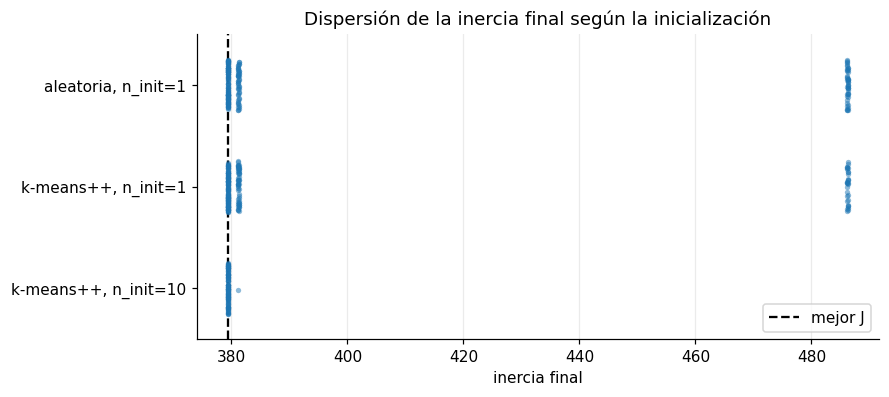

In [112]:
def inercias_corridas(init, n_init, n=200, k=3):
    return np.array([KMeans(k, init=init, n_init=n_init, random_state=s).fit(Z).inertia_ for s in range(n)])

J_ref = KMeans(3, n_init=100, random_state=SEED).fit(Z).inertia_     # mejor solución conocida (100 reinicios)
configs = {"aleatoria, n_init=1": ("random", 1), "k-means++, n_init=1": ("k-means++", 1),
           "k-means++, n_init=10": ("k-means++", 10)}
resultados_init = {nombre: inercias_corridas(*cfg, n=200 if cfg[1] == 1 else 100) for nombre, cfg in configs.items()}

tabla_init = pd.DataFrame({
    nombre: dict(J_min=J.min(), J_max=J.max(),
                 pct_alcanza_mejor=100 * np.mean(J <= J_ref * 1.0001))
    for nombre, J in resultados_init.items()}).T
display(tabla_init)

fig, ax = plt.subplots(figsize=(8, 3.6))
sns.stripplot(data=pd.DataFrame(dict(J=np.concatenate(list(resultados_init.values())),
                                     config=np.repeat(list(resultados_init), [len(v) for v in resultados_init.values()]))),
              x="J", y="config", ax=ax, size=3.5, alpha=0.5, jitter=0.25)
ax.axvline(J_ref, color="k", ls="--", label="mejor J")
ax.set(xlabel="inercia final", ylabel="", title="Dispersión de la inercia final según la inicialización")
ax.legend(); plt.show()

> **Observación:** Con **una sola** inicialización, aproximadamente la mitad de las corridas termina en un óptimo local peor que el mejor (k-means++ mejora un poco el porcentaje, pero no lo elimina). Con **varios reinicios** (`n_init=10` o más) casi siempre se alcanza la mejor solución. Por eso en el modelo final se usa k-means++ con `n_init=50` y una semilla fija (`random_state`) para que el resultado sea reproducible.

## 3.7 Modelo final

Se ajusta con un `Pipeline` (escalador + k-means), de modo que el mismo preprocesamiento se aplica automáticamente a datos nuevos. Como los números de grupo son **arbitrarios**, los reordenamos por masa corporal media creciente (para que "grupo 0" sea siempre el más liviano) y así los resultados sean comparables entre ejecuciones.

In [114]:
K_FINAL = 3
modelo = Pipeline([
    ("escalador", StandardScaler()),
    ("kmeans", KMeans(n_clusters=K_FINAL, init="k-means++", n_init=50, max_iter=300,
                      tol=1e-4, random_state=SEED)),
]).fit(X_df)

km = modelo.named_steps["kmeans"]
print(f"Convergió en {km.n_iter_} iteraciones | inercia J = {km.inertia_:.2f} | "
      f"inercia/n = {km.inertia_ / len(X_df):.3f}")

# Reordenar etiquetas por masa corporal media creciente
centros_orig = modelo.named_steps["escalador"].inverse_transform(km.cluster_centers_)
orden = np.argsort(centros_orig[:, variables.index("body_mass_g")])
rango_etiqueta = np.empty(K_FINAL, dtype=int)
rango_etiqueta[orden] = np.arange(K_FINAL)

def etiquetar(X_nuevo):
    """Etiqueta ordenada (0 = grupo más liviano) para datos con las columnas de `variables`."""
    return rango_etiqueta[modelo.predict(X_nuevo[variables])]

datos["grupo"] = etiquetar(X_df)
print("Tamaño de los grupos:", datos["grupo"].value_counts().sort_index().to_dict())

Convergió en 5 iteraciones | inercia J = 379.39 | inercia/n = 1.109
Tamaño de los grupos: {0: 132, 1: 87, 2: 123}


## 3.8 Perfilado e interpretación

**Perfilar** es describir cada grupo para entender qué significa: cuántos elementos tiene, cuáles son sus valores medios y **qué variables lo distinguen** de los demás. Es el paso que convierte "grupo 0, 1, 2" en algo interpretable.

Para ello hay que **volver a las unidades originales** (los centroides en el espacio estandarizado no se pueden leer directamente). Mostramos tamaños, centroides en unidades originales, el perfil en $z$-scores (un valor positivo significa "por encima del promedio global" y uno negativo "por debajo": sirve para ver rápido en qué se diferencia cada grupo) y las distribuciones por grupo.

,n,%,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
grupo 0,132,38.596,38.208,18.111,188.402,"3,584.659"
grupo 1,87,25.439,47.525,18.762,196.897,"3,902.011"
grupo 2,123,35.965,47.505,14.982,217.187,"5,076.016"


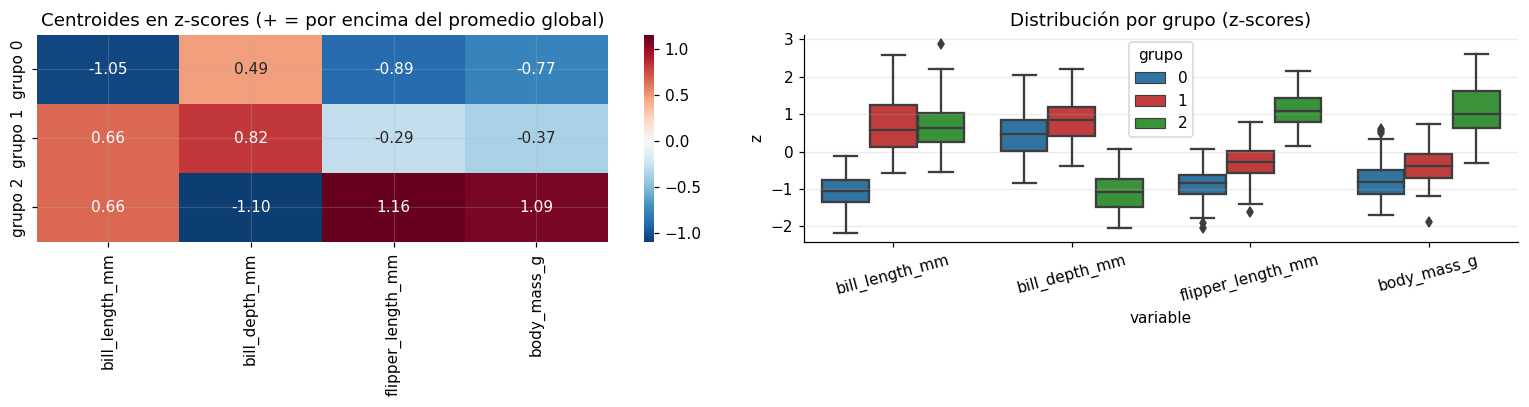

In [116]:
centros_ord = centros_orig[orden]                                   # centroides en unidades originales, ya ordenados
perfil3 = pd.DataFrame(centros_ord, columns=variables, index=[f"grupo {g}" for g in range(K_FINAL)])
perfil3.insert(0, "n", datos["grupo"].value_counts().sort_index().values)
perfil3.insert(1, "%", 100 * perfil3["n"] / perfil3["n"].sum())
display(perfil3)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
z_ord = km.cluster_centers_[orden]
sns.heatmap(pd.DataFrame(z_ord, columns=variables, index=perfil3.index), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("Centroides en z-scores (+ = por encima del promedio global)")
datos_largo = datos.melt(id_vars="grupo", value_vars=variables, var_name="variable", value_name="valor")
datos_largo["z"] = datos_largo.groupby("variable")["valor"].transform(lambda s: (s - s.mean()) / s.std())
sns.boxplot(data=datos_largo, x="variable", y="z", hue="grupo", palette=PALETA[:K_FINAL], ax=axes[1])
axes[1].set_title("Distribución por grupo (z-scores)"); axes[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()

### Visualización en 2D con PCA

Con 4 variables no se puede dibujar el agrupamiento directamente. Necesitamos **resumir** las 4 variables en 2 para poder hacer un gráfico.

#### ¿Qué es PCA?

El **análisis de componentes principales** construye ejes nuevos, llamados *componentes principales* (PC1, PC2, …). Cada uno es una **combinación** de las variables originales, y están ordenados por cuánta variabilidad de los datos capturan: PC1 captura la mayor posible, PC2 la mayor de lo que queda, etc. Quedarse con PC1 y PC2 da un mapa 2D que conserva la mayor parte de la información.

#### Cómo leer la salida

* **Varianza explicada:** porcentaje de la variabilidad total que conserva el mapa. Si es alto (aquí, cerca del 88 %), el mapa es fiel.
* **Tabla de cargas** (`components_`): dice cómo se forma cada eje. Por ejemplo, si PC1 tiene cargas positivas y grandes en aleta y masa corporal, PC1 se puede leer como un eje de "tamaño corporal".
* **Rombos blancos:** los centroides, proyectados al mismo mapa.

#### Dos advertencias

1. **PCA no forma parte de k-means.** El agrupamiento se hizo con las 4 variables estandarizadas; PCA solo sirve para *dibujar*.
2. Grupos que parecen **solaparse** en el mapa pueden estar separados en las dimensiones que el mapa no muestra (el ≈ 12 % de variabilidad restante).

Varianza explicada por PC1 y PC2: [0.688 0.193] → total 88.2%


,PC1,PC2
bill_length_mm,0.455,0.597
bill_depth_mm,-0.400,0.798
flipper_length_mm,0.576,0.002
body_mass_g,0.548,0.084


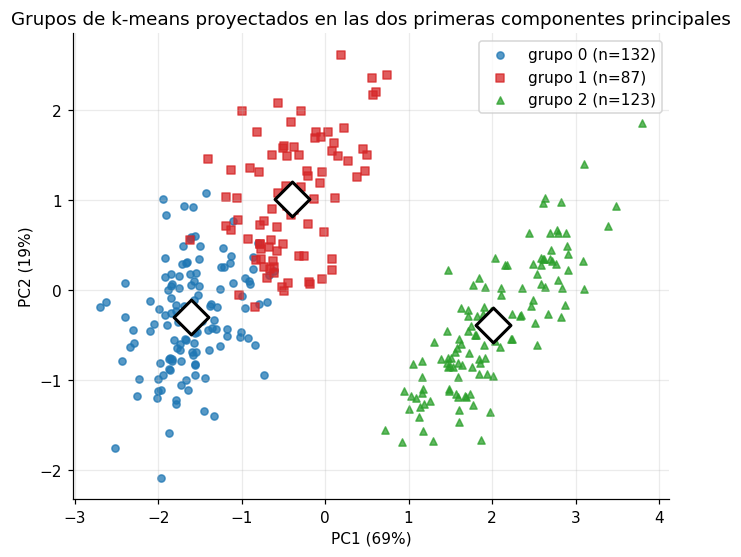

In [118]:
pca = PCA(n_components=2).fit(Z)
P = pca.transform(Z)
P_centros = pca.transform(km.cluster_centers_[orden])
print("Varianza explicada por PC1 y PC2:", pca.explained_variance_ratio_.round(3),
      f"→ total {pca.explained_variance_ratio_.sum():.1%}")
display(pd.DataFrame(pca.components_.T, index=variables, columns=["PC1", "PC2"]).round(3))

fig, ax = plt.subplots(figsize=(7, 5.5))
for g in range(K_FINAL):
    m = (datos["grupo"] == g).to_numpy()
    ax.scatter(P[m, 0], P[m, 1], s=22, alpha=0.75, color=PALETA[g], marker=MARCAS[g], label=f"grupo {g} (n={m.sum()})")
    ax.scatter(*P_centros[g], s=260, marker="D", facecolor="white", edgecolor="k", linewidth=2, zorder=5)
ax.set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})",
       title="Grupos de k-means proyectados en las dos primeras componentes principales")
ax.legend(); plt.show()

## 3.9 Validación

### Validación interna (sin etiquetas)

In [120]:
s_i = silhouette_samples(Z, datos["grupo"])
print(f"Silueta media global: {s_i.mean():.3f}")
display(pd.DataFrame({"silueta media": pd.Series(s_i).groupby(datos["grupo"].to_numpy()).mean(),
                      "% con silueta < 0": pd.Series(s_i < 0).groupby(datos["grupo"].to_numpy()).mean() * 100}))

Silueta media global: 0.447


,silueta media,% con silueta < 0
0,0.431,0.000
1,0.301,5.747
2,0.568,0.000


### Validación externa (con la especie, que **nunca** se usó para entrenar)

#### ¿Qué significa "validar con una variable que no se usó"?

Hay dos tipos de validación:

* **Interna:** ¿los grupos son compactos y están separados *según los propios datos*? (silueta, etc.).
* **Externa:** ¿los grupos coinciden con una **referencia independiente**? Aquí esa referencia es la **especie**. Como la guardamos aparte (`meta`) y el modelo nunca la vio, compararla no es trampa: es como un examen cuyas respuestas el modelo no conocía.

#### ¿Por qué no calcular simplemente el accuracy?

Porque los números de grupo son **arbitrarios**: el "grupo 0" podría ser cualquiera de las especies. Se usan medidas que no dependen de cómo se numeren los grupos:

| Medida | Qué responde |
|---|---|
| **Tabla de contingencia** | Cuántos pingüinos de cada especie cayeron en cada grupo (filas: grupos; columnas: especies) |
| **ARI** | Qué tan parecida es la partición a la de las especies (1 = idéntica, ≈ 0 = azar) |
| **NMI** | Cuánta información comparten ambas particiones (0 a 1) |
| **Homogeneidad** | ¿Cada grupo contiene casi una sola especie? |
| **Completitud** | ¿Cada especie queda casi toda en un solo grupo? |
| **Medida V** | Promedio armónico de homogeneidad y completitud |
| **Pureza** | Fracción de pingüinos que pertenecen a la especie mayoritaria de su grupo |

> **Advertencia.** La especie es una referencia razonable, no "la verdad" del clustering: los grupos podrían reflejar otra estructura legítima (por ejemplo, tamaño o sexo). Y en problemas reales normalmente **no existe** tal referencia.

In [122]:
tab = pd.crosstab(datos["grupo"], meta["species"], rownames=["grupo k-means"], colnames=["especie"])
display(tab)

ari = adjusted_rand_score(meta["species"], datos["grupo"])
nmi = normalized_mutual_info_score(meta["species"], datos["grupo"])
hom, comp, vm = homogeneity_completeness_v_measure(meta["species"], datos["grupo"])
pureza = tab.max(axis=1).sum() / tab.values.sum()
display(pd.Series(dict(ARI=ari, NMI=nmi, homogeneidad=hom, completitud=comp, medida_V=vm, pureza=pureza),
                  name="valor").to_frame())

# Pingüinos "mal ubicados": su especie no es la mayoritaria de su grupo
especie_mayoritaria = tab.idxmax(axis=1)
mal = datos[datos["species"] != datos["grupo"].map(especie_mayoritaria)]
print(f"Pingüinos cuya especie no es la mayoritaria de su grupo: {len(mal)} de {len(datos)}")
display(mal[["species", "island", "sex"] + variables + ["grupo"]].head(10))

especie,Adelie,Chinstrap,Gentoo
grupo k-means,,,
0,127,5,0
1,24,63,0
2,0,0,123


,valor
ARI,0.793
NMI,0.786
homogeneidad,0.798
completitud,0.773
medida_V,0.786
pureza,0.915


Pingüinos cuya especie no es la mayoritaria de su grupo: 29 de 342


,species,island,sex,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,grupo
8,Adelie,Torgersen,NaN,42.000,20.200,190.000,"4,250.000",1
16,Adelie,Torgersen,MALE,42.500,20.700,197.000,"4,500.000",1
18,Adelie,Torgersen,MALE,46.000,21.500,194.000,"4,200.000",1
42,Adelie,Dream,MALE,44.100,19.700,196.000,"4,400.000",1
48,Adelie,Dream,MALE,42.300,21.200,191.000,"4,150.000",1
52,Adelie,Biscoe,MALE,42.000,19.500,200.000,"4,050.000",1
60,Adelie,Biscoe,MALE,41.300,21.100,195.000,"4,400.000",1
68,Adelie,Torgersen,MALE,41.800,19.400,198.000,"4,450.000",1
72,Adelie,Torgersen,MALE,45.800,18.900,197.000,"4,150.000",1
74,Adelie,Torgersen,MALE,42.800,18.500,195.000,"4,250.000",1


**Otras variables de interpretación** (tampoco usadas para entrenar): el **sexo** y la **isla**. Los machos son en promedio más grandes que las hembras en las tres especies (dimorfismo sexual), lo que puede mezclar el efecto "especie" con el efecto "sexo" en las medidas.

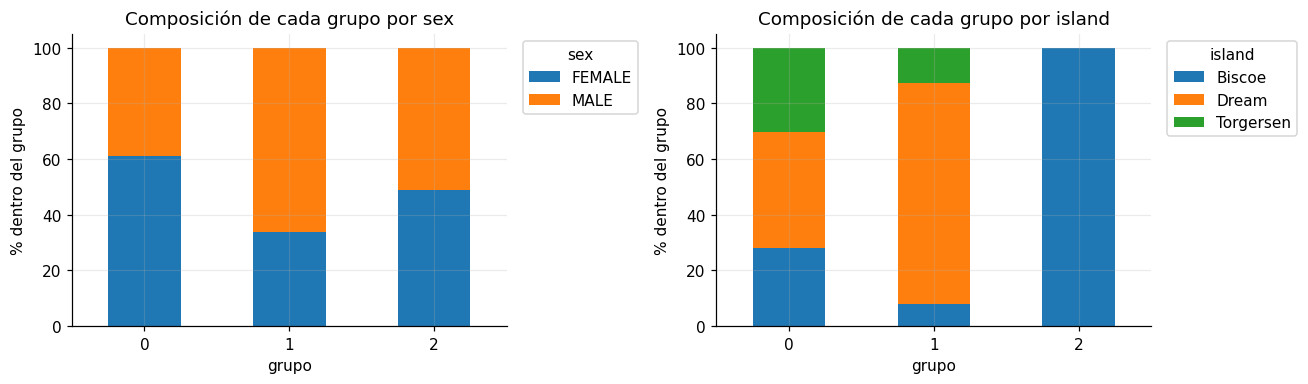

In [124]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, col in zip(axes, ["sex", "island"]):
    pd.crosstab(datos["grupo"], meta[col], normalize="index").mul(100).plot.bar(stacked=True, ax=ax, rot=0)
    ax.set(ylabel="% dentro del grupo", xlabel="grupo", title=f"Composición de cada grupo por {col}")
    ax.legend(title=col, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

> **Lectura.** Sin haber visto nunca la especie, k-means separa a la perfección a *Gentoo* (grupo 2) y divide a las otras dos especies en dos grupos que solo coinciden en parte con ellas (ARI ≈ 0.8, pureza ≈ 0.9). Los errores se concentran en el solapamiento entre *Adelie* y *Chinstrap*: el grupo 1 reúne a casi todos los *Chinstrap* pero también a 24 *Adelie* (todos machos, salvo uno de sexo desconocido), que son más grandes y de picos más profundos (dimorfismo sexual; ver el gráfico de composición por sexo). Recuerde que en un proyecto real normalmente **no habrá una especie** con la cual validar: por eso son tan importantes los criterios internos, la estabilidad y la interpretación con expertos del dominio.

## 3.10 ¿Qué habría pasado si…? Efecto de las decisiones técnicas

Comparamos el modelo final con variantes (solo con fines pedagógicos, usando la especie como referencia externa). La silueta se calcula siempre en el espacio estandarizado para que sea comparable. Dos de las variantes son métodos que quizá no conozca; antes de verlas, una explicación breve.

### ¿Qué es una mezcla gaussiana?

K-means asigna cada punto a **un único grupo** (asignación "dura") y, sin decirlo, supone que los grupos son nubes **redondas** de tamaño parecido. La **mezcla gaussiana** (*Gaussian Mixture Model*, GMM) es un modelo probabilístico que relaja esos supuestos:

* Supone que los datos salen de **$k$ distribuciones normales** ("campanas" en varias dimensiones). Cada una tiene su propio **centro** (media), su propia **forma y tamaño** (matriz de covarianza) y un **peso** (qué proporción de los datos genera).
* Para cada punto calcula la **probabilidad de pertenecer a cada grupo** (asignación "blanda"): por ejemplo, 70 % grupo A y 30 % grupo B. Un punto en la frontera entre dos nubes queda con probabilidades repartidas, en vez de forzarlo a un solo grupo.
* Se ajusta con el algoritmo **EM**, que se parece mucho al de Lloyd: el *paso E* calcula probabilidades (análogo a **asignar**) y el *paso M* recalcula medias, covarianzas y pesos (análogo a **actualizar**).

El parámetro `covariance_type` controla la forma permitida de cada campana:

| `covariance_type` | Forma de cada grupo | Comentario |
|---|---|---|
| `"spherical"` | Nube **redonda**, con tamaño propio | Es el análogo probabilístico de k-means |
| `"full"` | **Elipse** de cualquier forma y orientación | La más flexible; útil cuando las variables están correlacionadas dentro de cada grupo (aquí, aleta y masa) |

### ¿Y el método jerárquico de Ward?

Empieza con cada pingüino como su propio grupo y, paso a paso, **fusiona los dos grupos cuya unión aumenta menos la varianza intra-grupo**, hasta quedar con $k$ grupos. No necesita centros iniciales (es determinista) ni supone grupos estrictamente esféricos.

### La comparación

Las columnas: `ARI_especie` y `NMI_especie` (concordancia con la especie, más alto es mejor) y `silueta_Z` (separación interna en el espacio estandarizado).

In [126]:
variantes = {}
variantes["k-means SIN escalar (k=3)"] = KMeans(3, n_init=50, random_state=SEED).fit_predict(X_df.to_numpy())
for k in (2, 3, 4):
    variantes[f"k-means escalado (k={k})" + (" ← final" if k == 3 else "")] = \
        KMeans(k, n_init=50, random_state=SEED).fit_predict(Z)
variantes["Mezcla gaussiana, cov. completa (k=3)"] = GaussianMixture(3, covariance_type="full", n_init=10, random_state=SEED).fit_predict(Z)
variantes["Mezcla gaussiana, cov. esférica (k=3)"] = GaussianMixture(3, covariance_type="spherical", n_init=10, random_state=SEED).fit_predict(Z)
variantes["Jerárquico Ward (k=3)"] = AgglomerativeClustering(3, linkage="ward").fit_predict(Z)

comparacion = pd.DataFrame({
    nombre: dict(ARI_especie=adjusted_rand_score(meta["species"], lab),
                 NMI_especie=normalized_mutual_info_score(meta["species"], lab),
                 silueta_Z=silhouette_score(Z, lab))
    for nombre, lab in variantes.items()}).T
display(comparacion.sort_values("ARI_especie", ascending=False))

,ARI_especie,NMI_especie,silueta_Z
"Mezcla gaussiana, cov. completa (k=3)",0.960,0.935,0.455
Jerárquico Ward (k=3),0.916,0.901,0.454
"Mezcla gaussiana, cov. esférica (k=3)",0.873,0.838,0.459
k-means escalado (k=3) ← final,0.793,0.786,0.447
k-means escalado (k=2),0.655,0.767,0.532
k-means escalado (k=4),0.637,0.704,0.400
k-means SIN escalar (k=3),0.319,0.401,0.248


> **Observación**
> * **Escalado:** sin escalar, k-means agrupa casi solo por masa corporal y el ARI cae a ≈ 0.3, frente a ≈ 0.8 con escalado: es el error de preprocesamiento más frecuente y más costoso.
> * **Elección de $k$:** con $k=2$ la silueta es la mejor (grupos "más limpios") pero se fusionan dos especies; con $k=4$ se subdivide más y la concordancia con las especies baja. Que la silueta sea máxima no significa que la partición responda mejor a la pregunta de negocio o científica.
> * **Otros algoritmos:** la mezcla gaussiana de covarianza completa (grupos elípticos de distinta forma y orientación) ajusta aquí claramente mejor (ARI ≈ 0.96 frente a ≈ 0.79), y el método jerárquico de Ward también supera a k-means. Esto recuerda los **supuestos implícitos de k-means**: grupos aproximadamente esféricos y de tamaño similar. Con covarianza esférica la mezcla gaussiana es, en teoría, el análogo probabilístico de k-means, aunque aquí también mejora el resultado porque permite grupos de distinto tamaño y asigna con probabilidades.

### Asignación "blanda": es lo que k-means no puede decir

K-means entrega una etiqueta y nada más. La mezcla gaussiana, además, indica **qué tan segura** es esa asignación. Veamos los pingüinos con la asignación **más incierta** (probabilidad máxima más baja) y comparemos con lo que dice k-means.

In [131]:
gmm = GaussianMixture(3, covariance_type="full", n_init=10, random_state=SEED).fit(Z)
prob = gmm.predict_proba(Z)                                   # probabilidad de pertenecer a cada componente
print(f"Pingüinos con probabilidad máxima > 95 %: {np.mean(prob.max(axis=1) > 0.95):.1%}")

dudosos = np.argsort(prob.max(axis=1))[:8]                    # los 8 más inciertos
tabla_prob = pd.DataFrame(prob[dudosos], columns=[f"P(componente {j})" for j in range(3)])
tabla_prob.insert(0, "especie real", meta["species"].to_numpy()[dudosos])
tabla_prob.insert(1, "grupo k-means", datos["grupo"].to_numpy()[dudosos])
display(tabla_prob)

Pingüinos con probabilidad máxima > 95 %: 96.2%


,especie real,grupo k-means,P(componente 0),P(componente 1),P(componente 2)
0,Chinstrap,0,0.430,0.000,0.570
1,Chinstrap,0,0.602,0.000,0.398
2,Chinstrap,1,0.321,0.000,0.679
3,Adelie,1,0.274,0.000,0.726
4,Adelie,1,0.780,0.000,0.220
5,Chinstrap,0,0.821,0.000,0.179
6,Chinstrap,1,0.111,0.000,0.889
7,Chinstrap,1,0.096,0.000,0.904


> **Observación:** La gran mayoría de los pingüinos se asigna con probabilidad casi 1, pero hay unos pocos "dudosos" con probabilidades repartidas entre dos componentes: son justamente los que están en la zona de solapamiento entre *Adelie* y *Chinstrap*, donde k-means debe forzar una decisión. (La numeración de los componentes de la mezcla es arbitraria, igual que la de los grupos de k-means; aquí lo importante es que dos de las tres probabilidades suman casi 1, es decir, la duda está entre dos grupos.) Esa información de **incertidumbre** es una ventaja de los modelos probabilísticos.

## 3.11 Datos nuevos y despliegue

Para asignar un pingüino nuevo basta con `modelo.predict`, porque el `Pipeline` aplica el **mismo escalado** del entrenamiento. Además, la distancia al centroide permite detectar observaciones **atípicas** (muy lejos de todo grupo), un aviso de que el modelo quizá no sea apropiado para ese caso. Como umbral usamos el percentil 99 de las distancias de entrenamiento.

In [135]:
dist_train = modelo.transform(X_df)[np.arange(len(X_df)), modelo.predict(X_df)]   # distancia (en z) al propio centroide
umbral = np.percentile(dist_train, 99)

nuevos = pd.DataFrame({
    "bill_length_mm":    [39.0, 48.5, 50.0, 60.0],
    "bill_depth_mm":     [18.5, 15.0, 15.5, 25.0],
    "flipper_length_mm": [190, 215, 220, 250],
    "body_mass_g":       [3600, 5000, 5400, 9000],
}, index=["nuevo 1", "nuevo 2", "nuevo 3", "nuevo 4 (extremo)"])

dist_n = modelo.transform(nuevos)
salida = nuevos.copy()
salida["grupo"] = etiquetar(nuevos)
salida["distancia_a_su_centroide"] = dist_n[np.arange(len(nuevos)), modelo.predict(nuevos)]
salida["¿atípico? (> p99 entrenamiento)"] = salida["distancia_a_su_centroide"] > umbral
print(f"Umbral (percentil 99 de distancias de entrenamiento): {umbral:.3f}")
display(salida)

Umbral (percentil 99 de distancias de entrenamiento): 2.032


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,grupo,distancia_a_su_centroide,¿atípico? (> p99 entrenamiento)
nuevo 1,39.000,18.500,190,3600,0,0.271,False
nuevo 2,48.500,15.000,215,5000,2,0.258,False
nuevo 3,50.000,15.500,220,5400,2,0.694,False
nuevo 4 (extremo),60.000,25.000,250,9000,2,7.780,True


**Guardar y reutilizar el modelo.** Se guarda el `Pipeline` completo (escalador + k-means) junto con el orden de etiquetas, y se comprueba que al recargarlo se obtienen las mismas asignaciones.

In [137]:
import joblib, tempfile, os
ruta = os.path.join(tempfile.gettempdir(), "modelo_kmeans_pinguinos.joblib")
joblib.dump(dict(modelo=modelo, rango_etiqueta=rango_etiqueta, variables=variables, k=K_FINAL), ruta)

cargado = joblib.load(ruta)
etiq_recargadas = cargado["rango_etiqueta"][cargado["modelo"].predict(X_df[cargado["variables"]])]
print("Modelo guardado en:", ruta)
print("¿Las asignaciones tras recargar coinciden?", np.array_equal(etiq_recargadas, datos["grupo"].to_numpy()))

Modelo guardado en: /var/folders/kh/8_x8gdnd71qdr1yk_k0xnffr0000gn/T/modelo_kmeans_pinguinos.joblib
¿Las asignaciones tras recargar coinciden? True


## 3.12 Conclusiones y lista de verificación

**Lo bueno:** Solo con cuatro medidas corporales, k-means identifica tres grupos de pingüinos que corresponden en gran medida a las tres especies, con la mayor separación entre *Gentoo* (más grandes, picos menos profundos y aletas largas) y las otras dos. La decisión de $k$ no fue trivial: distintos criterios sugieren $k=2$ o $k=3$.

**Lo malo:**
* K-means supone grupos aproximadamente esféricos y de tamaño similar; el solapamiento entre *Adelie* y *Chinstrap* y el dimorfismo sexual lo ponen a prueba.
* Siempre devuelve $k$ grupos, haya o no estructura real: la validez hay que **demostrarla** (criterios internos, estabilidad, sentido en el dominio).
* Los resultados dependen de la escala, de las variables escogidas y de la distancia.
* Con datos reales rara vez existe una etiqueta de referencia como la especie.

**Para finalizar recuerden que cada vez que se hace un k-means  a un problema realse hace todo lo que se hizo en este u2ltimo ejemplo, asi que podemos resumir todo el trabajo, y siempre con esta técnica será casi igual, en la siguiente lista de verificación al aplicar k-means**

| ✔ | Paso | Pregunta de control |
|---|---|---|
| ☐ | Datos faltantes y duplicados | ¿Los eliminé o imputé con criterio (sin fabricar estructura)? |
| ☐ | Variables | ¿Son numéricas y relevantes? ¿Hay redundancia (alta correlación) o categóricas mal codificadas? |
| ☐ | Atípicos y asimetría | ¿Hay valores extremos que arrastren centroides? ¿Conviene una transformación (por ejemplo, logarítmica en variables de dinero)? |
| ☐ | Escalado | ¿Estandaricé con parámetros guardados del entrenamiento? |
| ☐ | Elección de $k$ | ¿Usé varios criterios (codo, silueta, gap, CH, DB) y el sentido del problema? |
| ☐ | Inicialización | ¿k-means++, `n_init` ≥ 10 y `random_state` fijo? |
| ☐ | Estabilidad | ¿Los grupos se sostienen con remuestreo? |
| ☐ | Interpretación | ¿Perfilé los grupos en unidades originales y les di sentido junto con expertos? |
| ☐ | Validación | ¿Usé métricas internas y, si existe, referencia externa? |
| ☐ | Despliegue | ¿Guardé el `Pipeline` completo? ¿Monitoreo atípicos y deriva en datos nuevos? |

**Para seguir practicando:** Repitan el análisis con otro conjunto de datos real, un buen ejemplo es el *Wholesale customers* (UCI Machine Learning Repository: gasto anual de clientes de un distribuidor mayorista en seis categorías de producto). Allí las variables de gasto son muy asimétricas, por lo que conviene probar ademas de la lista de verificación, una **transformación logarítmica** antes de escalar, y comparar los resultados con la columna `Channel` como referencia externa.

**Finalmente para ver mas todo esto en detalle pueden consultar estas referencias**

Gorman, K. B., Williams, T. D. y Fraser, W. R. (2014), *Ecological sexual dimorphism and environmental variability within a community of Antarctic penguins*, PLoS ONE. Horst, A. M., Hill, A. P. y Gorman, K. B. (2020), *palmerpenguins* (paquete de R). Arthur, D. y Vassilvitskii, S. (2007), *k-means++: the advantages of careful seeding*. Rousseeuw, P. J. (1987), *Silhouettes*. Tibshirani, R., Walther, G. y Hastie, T. (2001), *Estimating the number of clusters in a data set via the gap statistic*.